# План теста — справочник

> **Полная версия лекции, справочник.** На встрече используется `theory.ipynb` (сжатая теория) и `practice.ipynb` (задания). Здесь — все выкладки и симуляции целиком.

На встрече 1 мы решили, стоит ли вообще тестировать изменение, и подобрали α и n. В примерах ниже стоят стандартные α = 0.05 и β = 0.2; на кейсе чекаута α берётся из вердикта встречи 1 (см. `../01. Стоит ли тестировать и на чём измерять/lesson.ipynb`, раздел «Вердикт для кейса»). Теперь составляем сам план теста: как устроен A/B-тест, что и в каком порядке мерить и как ускорить сам тест.

## Часть 1. Как устроен A/B-тест

Сначала соберём каркас: от гипотезы через метрику и критерий к решению, а затем выберем критерий под тип метрики.

In [1]:
from dataclasses import dataclass
from typing import List, Literal, Optional, Sequence, TypedDict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import statsmodels.api as sm
from ipywidgets import FloatSlider, IntSlider, interact
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from numpy.typing import NDArray
from statsmodels.stats.proportion import proportion_confint

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.figsize'] = (16, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

FloatArray = NDArray[np.float64]

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE, ORANGE = '#8172B3', '#DD8452'
ALPHA = 0.05


def masked_mean_var(x: np.ndarray, mask: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Считает среднее, дисперсию и размер выборки по строкам x, учитывая только наблюдения из mask."""
    n = mask.sum(axis=1)
    mean = (x * mask).sum(axis=1) / n
    var = ((x ** 2 * mask).sum(axis=1) - n * mean ** 2) / (n - 1)
    return mean, var, n


def z_pvalue(delta: np.ndarray, se: np.ndarray) -> np.ndarray:
    """Возвращает двустороннее p-value для разницы delta со стандартной ошибкой se."""
    return 2 * stats.norm.sf(np.abs(delta / se))


def rate_with_ci(rejected: np.ndarray) -> tuple[float, float, float]:
    """Возвращает долю отклонений H0 и её 95% ДИ Уилсона."""
    low, high = proportion_confint(rejected.sum(), rejected.size, method='wilson')
    return float(rejected.mean()), float(low), float(high)


def plot_rates(ax: plt.Axes, rates: dict[str, np.ndarray], title: str, reference: float | None = ALPHA) -> None:
    """Рисует доли отклонений H0 с 95% ДИ: одна точка на метод."""
    names = list(rates)[::-1]
    values = np.array([rate_with_ci(rates[name]) for name in names])
    ax.errorbar(values[:, 0], names, xerr=[values[:, 0] - values[:, 1], values[:, 2] - values[:, 0]],
                fmt='o', color=BLUE, capsize=4)
    if reference is not None:
        ax.axvline(reference, color=RED, linestyle='--', label=f'Заявленный уровень {reference:.0%}')
        ax.legend(loc='lower right')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.set_title(title)


## Пайплайн тестирования гипотез

Эффективное научное исследование требует тщательно формализованного подхода. Этот процесс включает в себя ряд последовательных шагов, от первоначальной гипотезы до окончательного внедрения результатов, и предполагает сложную систему взаимодействия между различными командами.

В общем случае тестирование представляет из себя следующую цепочку событий:

```
1. Формулирование гипотезы
2. Прототипирование дизайна тестирования
3. Сбор данных
4. Анализ данных
5. Формулирование итогов гипотезы
6. Подтверждение/Опровержение тестируемой гипотезы
7. Внедрение/ Отказ от внедрения
```

1.  **Формулирование гипотезы**

Начальный этап любого исследования – это формулировка проверяемой гипотезы. Гипотеза должна быть максимально точно сформулирована, чтобы не вносить недопонимание в трактовке другим командам, которые также участвуют в процессе тестирования. Как минимум гипотеза должна содержать:

* Контекст, почему хотим вносить изменение
* Вносимое изменение
* Целевая аудитория
* Ожидаемый эффект

Например,

* `Контекст`: На странице карточки товара Wildberries показывает динамику цены.
Сейчас там отображается средняя цена без учёта скидок кошелька, доставки и скидок по привилегии.
Тем не менее, Wildberries имеет СПП - скидка со стороны платформы, которая не учитывается в цене.
Как итог может быть ситуация, что на этой неделе скидка уменьшилась -> цены будут выше (при прочих равных),
что негативно скажется на ощущениях пользователя (хотя продавец цены не поднимал фактически и не виноват в этом).
* `Изменение`: Будем в динамике указывать чистую цену, выставленную продавцом
* `Целевая аудитория`: Все пользователи площадки WB
* `Ожидаемый эффект`: Более справедливое отображение цены увеличит конверсию в заказ,
  т.к. не будет неоправданных завышений в динамике

2.  **Дизайн исследования**

После формулировки гипотезы разрабатывается дизайн исследования, который является критически важным для минимизации систематической ошибки и обеспечения внутренней валидности результатов. На этом этапе досконально продумывается, как будет тестироваться выдвинутая гипотеза: выбирается метод тестирования, список метрик, статистический критерий, задаются минимальные статистические параметры теста.

Например,

* `Метод тестирования`: A/B тест
* `Метрики` : конверсия из просмотра в заказ при просмотре динамики цены
* `Статистический критерий`: t-test с применением дельта метода
* `Параметры теста`:
  * `ошибка 1 рода`: 5%
  * `ошибка 2 рода`: 20%
  * `MDE`: минимальный эффект, который хотим обнаружить, например +1% к конверсии
  * `размер выборки и длительность`: считаются из параметров выше

3.  **Сбор данных**

На этапе сбора данных реализуется разработанный дизайн. Это включает в себя набор участников, их распределение по группам согласно процедурам рандомизации и сокрытия распределения, а также проведение вмешательств и измерение исходов в соответствии с протоколом. Важно обеспечивать **единообразие воздействия** (treatment fidelity: все пользователи группы получают одно и то же изменение), контролировать уровень пропущенных данных и отсева участников, а также учитывать потенциально мешающие переменные.

4.  **Анализ данных**

После сбора данных следует этап их анализа для проверки гипотезы. Здесь важно предобработать данные и верно обсчитать метрики.

5.  **Формулирование итогов гипотезы**

После предобработки данных и получения итоговых метрик необходимо их правильно провалидировать с учётом возможных ошибок, которые были заложены в дизайн теста. Итогом в идеальном случае должен быть отчёт с метриками тестовой и контрольной групп и вывод на основе статистического критерия.

6. **Подтверждение/Опровержение тестируемой гипотезы**

На основе отчёта из предыдущего шага команда аналитики выносит вердикт, подтверждается гипотеза или нет.

7. **Внедрение/ Отказ от внедрения**

В зависимости от успеха проведенного исследования уже решается, будет ли фича 'катиться в прод' или необходимо её пересмотреть с учётом недостатков, выявленных при помощи эксперимента.

Так как исследование — комплексный процесс, в нём участвуют сразу несколько команд, каждая из которых отвечает за свою составляющую. В общем виде взаимодействие может выглядеть следующим образом:

*   **Продуктовая команда:** Инициирует гипотезы, исходя из потребностей пользователей, бизнес-целей или наблюдаемых проблем. Определяет, какое изменение или новая функция может улучшить ключевые метрики.
*   **Аналитическая команда:** Формализует гипотезы в измеряемые параметры. Совместно с продуктовой командой разрабатывает дизайн эксперимента, определяет необходимые метрики, рассчитывает размер выборки и планирует методы анализа данных. Также обеспечивает прозрачность и точность результатов.
*   **Команда разработки:** Реализует техническую часть эксперимента. Это может включать разработку новых функций, механизмов рандомизации пользователей, инструментов сбора данных и интеграцию с аналитическими системами. Обеспечивает техническую возможность проведения эксперимента в соответствии с дизайном.

Дальше работает итерационный цикл: после сбора данных аналитики проводят анализ, результаты которого возвращаются продуктовой команде для принятия решений о дальнейшем развитии продукта. Этот цикл повторяется, создавая культуру принятия решений, основанных на данных.

### Ошибки I и II рода

Напомним. **Ошибка I рода** α — отвергнуть $H_0$, когда эффекта нет (ложноположительный результат); стандарт для A/B-тестов — α = 5%. **Ошибка II рода** β — не отвергнуть $H_0$, когда эффект есть; **мощность** теста равна $1 - \beta$, обычно 80%. На картинке это площади под распределениями статистики при верной $H_0$ и при верной $H_1$:


In [2]:
def plot_error_distributions(delta: float = 2.5, se: float = 1.0, alpha: float = 0.05) -> None:
    """
    Показывает распределения статистики при H₀ и H₁ и подсвечивает ошибки I и II рода.

    Parameters
    ----------
    delta : float
        Эффект: сдвиг статистики при верной H₁.
    se : float
        Стандартная ошибка статистики.
    alpha : float
        Уровень значимости одностороннего Z-теста.
    """
    critical_value = stats.norm.ppf(1 - alpha, loc=0, scale=se)
    x_grid = np.linspace(-4 * se, delta + 4 * se, 1_000)
    pdf_null = stats.norm.pdf(x_grid, loc=0, scale=se)
    pdf_alt = stats.norm.pdf(x_grid, loc=delta, scale=se)
    beta = stats.norm.cdf(critical_value, loc=delta, scale=se)

    plt.figure(figsize=(14, 7))
    plt.plot(x_grid, pdf_null, label='$H_0$: эффекта нет', color='C0')
    plt.plot(x_grid, pdf_alt, label=f'$H_1$: эффект δ = {delta}', color='C1')
    plt.axvline(critical_value, color='k', linestyle='--', label='Критическое значение')

    mask_type_i = x_grid >= critical_value
    plt.fill_between(x_grid[mask_type_i], pdf_null[mask_type_i], color='C0', alpha=0.3,
                     label=f'Ошибка I рода: α = {alpha:.2f}')
    mask_type_ii = x_grid <= critical_value
    plt.fill_between(x_grid[mask_type_ii], pdf_alt[mask_type_ii], color='C1', alpha=0.3,
                     label=f'Ошибка II рода: β = {beta:.2f}')

    plt.title('Ошибки I и II рода в одностороннем Z-тесте')
    plt.xlabel('Значение статистики (разность средних)')
    plt.ylabel('Плотность')
    plt.legend(loc='upper right')
    plt.show()


def calculate_and_plot_mde(n: int = 1_000,
                           sigma: float = 1.0,
                           alpha: float = 0.05,
                           target_power: float = 0.8,
                           sides: int = 2) -> float:
    """
    Строит кривую мощности Z-теста для двух групп по n наблюдений и возвращает MDE.
    sides = 1 — односторонняя альтернатива (z_{1-α}), sides = 2 — двусторонняя (z_{1-α/2}).
    Для двустороннего теста кривая учитывает только «правильный» хвост: второй вклад пренебрежимо мал.
    """
    se = sigma * np.sqrt(2 / n)
    z_alpha = stats.norm.ppf(1 - alpha / sides)
    mde = (z_alpha + stats.norm.ppf(target_power)) * se

    delta_values = np.linspace(0, 2 * mde, 500)
    power_values = stats.norm.sf(z_alpha - delta_values / se)

    plt.figure(figsize=(14, 6))
    plt.plot(delta_values, power_values, label='Мощность 1-β(δ)', color='C0')
    plt.axhline(target_power, color='k', linestyle='--', label=f'Целевая мощность = {target_power:.2f}')
    plt.axvline(mde, color='r', linestyle='--', label=f'MDE ≈ {mde:.3f}')
    plt.scatter([mde], [target_power], color='r', zorder=3)
    plt.title(f"Мощность {'одно' if sides == 1 else 'дву'}стороннего Z-теста и MDE")
    plt.xlabel('Эффект δ')
    plt.ylabel('Мощность теста')
    plt.legend()
    plt.show()

    print(f'При n={n} в группе, σ={sigma:.2f}, α={alpha:.2f}, сторон={sides} и мощности {target_power:.2f} MDE ≈ {mde:.3f}')
    return float(mde)


def plot_pvalue_cdf(ax: plt.Axes, pvalues_aa: FloatArray, pvalues_ab: FloatArray, alpha: float, title: str) -> None:
    """Рисует эмпирические функции распределения p-value в A/A и A/B и отмечает α и мощность."""
    grid = np.linspace(0, 1, 1_000)
    estimate_alpha = float(np.mean(pvalues_aa < alpha))
    estimate_power = float(np.mean(pvalues_ab < alpha))

    ax.plot(grid, np.mean(pvalues_aa[:, None] < grid, axis=0), label='A/A эксперимент', color='#3498db')
    ax.plot(grid, np.mean(pvalues_ab[:, None] < grid, axis=0), label='A/B эксперимент', color='#e74c3c')
    ax.plot([alpha, alpha], [0, 1], '--k', alpha=0.6, label='Порог α')
    ax.plot([0, alpha], [estimate_alpha, estimate_alpha], '--', color='#2980b9', label=f'Эмпирическое α = {estimate_alpha:.3f}')
    ax.plot([0, alpha], [estimate_power, estimate_power], '--', color='#c0392b', label=f'Мощность = {estimate_power:.3f}')
    ax.plot([0, 1], [0, 1], '--k', alpha=0.4)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Значение p-value')
    ax.set_ylabel('Доля p-value < x')
    ax.legend(fontsize=10)

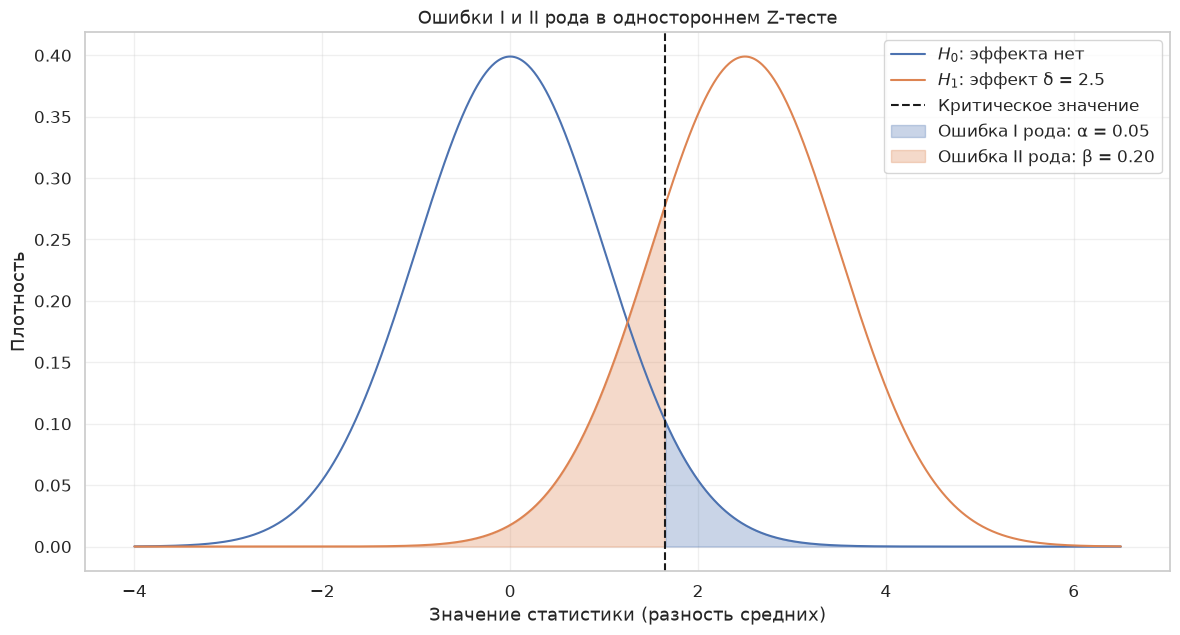

In [3]:
plot_error_distributions(delta=2.5, se=1.0, alpha=0.05)

### MDE

**MDE (Minimum Detectable Effect)** — наименьший эффект, который тест различает с вероятностью $1 - \beta$ (обычно 80%) при заданном α. Размер выборки и MDE — одна и та же формула, решённая относительно разных величин. Для разности средних в двух группах по $n$ наблюдений и сторонности $s$ ($s = 1$ — односторонняя альтернатива, $s = 2$ — двусторонняя):

$$
\text{MDE} = \left(z_{1-\alpha/s} + z_{1-\beta}\right)\sigma\sqrt{\frac{2}{n}}
\qquad\Longleftrightarrow\qquad
n = \frac{\left(z_{1-\alpha/s} + z_{1-\beta}\right)^2 \cdot 2\sigma^2}{\text{MDE}^2}.
$$

Сторонность фиксируется в дизайне один раз и используется и для MDE, и для $n$: иначе мы описываем два разных теста. Для неравного сплита $w_A, w_B$ множитель $2/n$ заменяется на $\frac{1}{w_A N} + \frac{1}{w_B N}$.

MDE убывает как $1/\sqrt{n}$: чтобы уменьшить его вдвое, выборку нужно увеличить вчетверо; второй рычаг — снизить дисперсию метрики (часть 3).


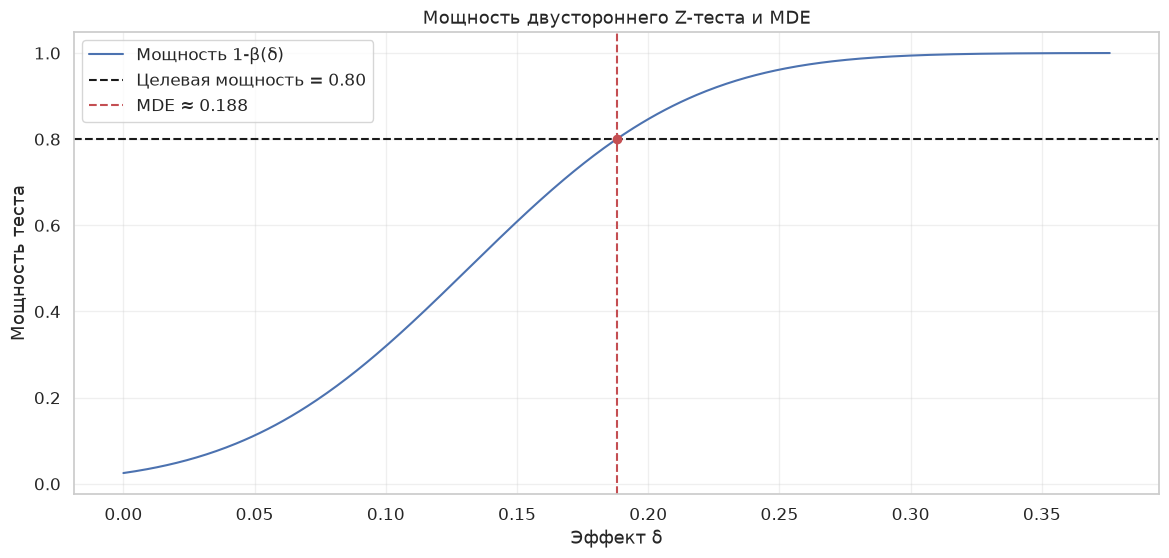

При n=1000 в группе, σ=1.50, α=0.05, сторон=2 и мощности 0.80 MDE ≈ 0.188


0.18793604977377518

In [4]:
calculate_and_plot_mde(n = 1000,
                       sigma = 1.5,
                       alpha = 0.05,
                       target_power = 0.8,
                       sides = 2)

## Виды тестов

Тесты различают по цели (что доказываем), по направленности (в какую сторону смотрим) и по критерию (чем считаем).


### Цель тестирования

По цели выделяют три вида тестов и отдельный случай — решение против порога безубыточности (μ — истинная разность «новое − старое», Δ — допуск):

| Вид | $H_0$ | $H_1$ | Что доказываем |
|---|---|---|---|
| Superiority (превосходство) | $\mu \le 0$ (двусторонний: $\mu = 0$) | $\mu > 0$ ($\mu \ne 0$) | новое лучше старого |
| Non-inferiority (не хуже) | $\mu \le -\Delta$ | $\mu > -\Delta$ | новое хуже не более чем на Δ |
| Equivalence (эквивалентность) | $\lvert\mu\rvert \ge \Delta$ | $\lvert\mu\rvert < \Delta$ | разность внутри ±Δ (TOST: два односторонних) |
| Против порога безубыточности | $\mu \le \theta_{BE}$ | $\mu > \theta_{BE}$ | внедрение окупается; $\theta_{BE}$ — из финмодели встречи 1 |

Граница superiority — ноль. MDE в гипотезу не входит: это параметр мощности, эффект, который тест заметит с вероятностью $1 - \beta$. Если решение принимается против $\theta_{BE}$, это другой тест: $n$ считается под эффект $\text{MDE} - \theta_{BE}$.


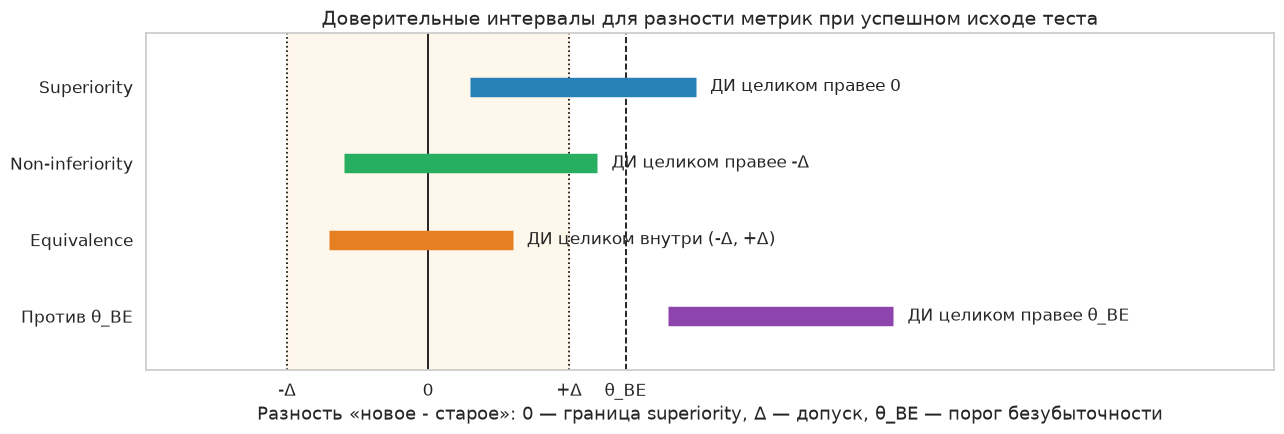

In [5]:
# Примеры доверительных интервалов для разности «новое - старое» при успешном исходе теста
margin, theta_be = 1.0, 1.4
examples = [
    ('Против θ_BE', (1.7, 3.3), '#8e44ad', 'ДИ целиком правее θ_BE'),
    ('Equivalence', (-0.7, 0.6), '#e67e22', 'ДИ целиком внутри (-Δ, +Δ)'),
    ('Non-inferiority', (-0.6, 1.2), '#27ae60', 'ДИ целиком правее -Δ'),
    ('Superiority', (0.3, 1.9), '#2980b9', 'ДИ целиком правее 0'),
]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.axvspan(-margin, margin, color='#f39c12', alpha=0.08)
for x, style in ((-margin, ':'), (0, '-'), (margin, ':'), (theta_be, '--')):
    ax.axvline(x, color='black', linestyle=style, linewidth=1.2)
for row, (name, (left, right), color, note) in enumerate(examples):
    ax.plot([left, right], [row, row], color=color, linewidth=14, solid_capstyle='butt')
    ax.text(right + 0.1, row, note, va='center', fontsize=12)
ax.set_yticks(range(len(examples)), labels=[e[0] for e in examples])
ax.set_xticks([-margin, 0, margin, theta_be], labels=['-Δ', '0', '+Δ', 'θ_BE'])
ax.set_xlabel('Разность «новое - старое»: 0 — граница superiority, Δ — допуск, θ_BE — порог безубыточности')
ax.set_xlim(-2, 6)
ax.set_ylim(-0.7, len(examples) - 0.3)
ax.grid(False)
ax.set_title('Доверительные интервалы для разности метрик при успешном исходе теста', fontsize=14)
plt.tight_layout()
plt.show()


### Направленность альтернативной гипотезы

Односторонний тест проверяет эффект в одну сторону (только рост или только падение), двусторонний — в любую. Направление фиксируют **до** старта: выбирать его по данным нельзя — фактический α удвоится. Guardrail-метрики обычно проверяют односторонне.


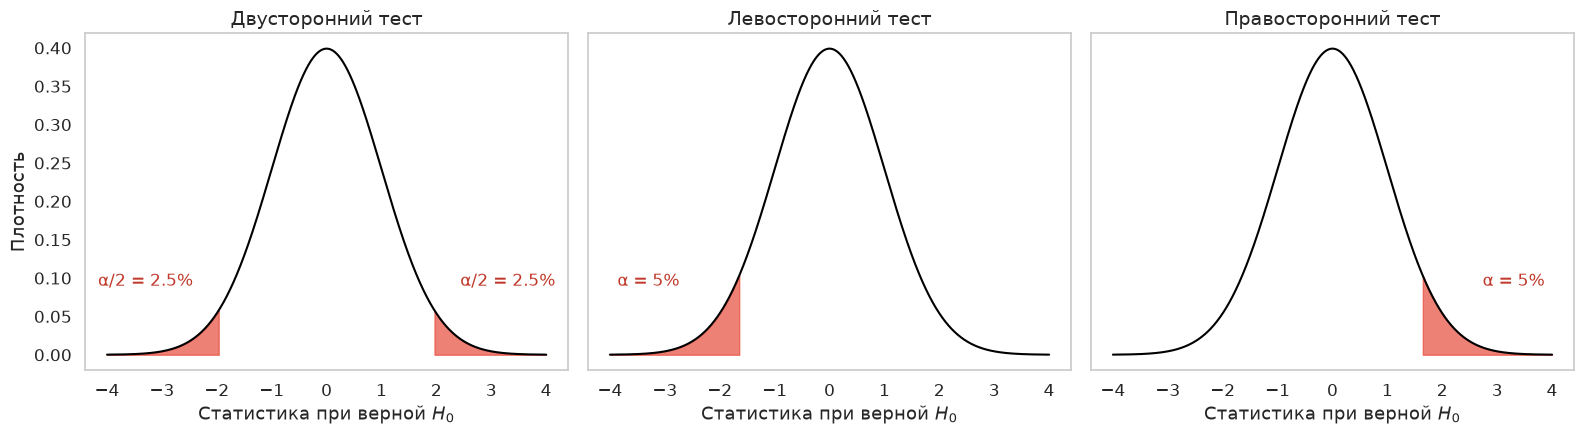

In [6]:
alpha = 0.05
x = np.linspace(-4, 4, 1_000)
pdf = stats.norm.pdf(x)
z_two, z_one = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(1 - alpha)

zones = [
    ('Двусторонний тест', [(x <= -z_two, 'α/2 = 2.5%', -3.3), (x >= z_two, 'α/2 = 2.5%', 3.3)]),
    ('Левосторонний тест', [(x <= -z_one, 'α = 5%', -3.3)]),
    ('Правосторонний тест', [(x >= z_one, 'α = 5%', 3.3)]),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (title, areas) in zip(axes, zones):
    ax.plot(x, pdf, color='black')
    for mask, label, x_text in areas:
        ax.fill_between(x[mask], pdf[mask], color='#e74c3c', alpha=0.7)
        ax.text(x_text, 0.09, label, ha='center', fontsize=12, color='#c0392b')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Статистика при верной $H_0$')
    ax.grid(False)
axes[0].set_ylabel('Плотность')
plt.tight_layout()
plt.show()

### Статистические критерии

Теперь переходим непосредственно к статистическим критериям - лакмусовым бумажкам, которые говорят, а является ли **статистически значимой** разница в метриках между тестовой и контрольной группой.

[Статистически значимая разница](https://en.wikipedia.org/wiki/Statistical_significance) — разница, которую трудно объяснить случайностью. Это не гарантия, что эффект есть: при верной $H_0$ значимый результат всё равно появится с вероятностью $\alpha$. Мерой служит p-value — вероятность получить такую или более экстремальную разницу при верной $H_0$. Это **не** вероятность того, что $H_0$ верна.

Есть несколько категорий критериев:
  * Параметрические - критерии, которые применяются к данным с определёнными распределениями
  * Непараметрические - критерии, которые не делают предположений о форме распределения данных

Вообще критериев существует огромное множество ([обзор 1](https://www.statskingdom.com/index.html) и [обзор 2](https://www.biostathandbook.com/testchoice.html)), но в онлайн A/B зачастую применяются следующие:

#### Параметрические тесты

##### $z$-тест

$z$-тест — это параметрический статистический тест, который используется для проверки гипотез о средних значениях одной или двух генеральных совокупностей. Z-тест традиционно применяется, когда известна дисперсия генеральной совокупности или когда размер выборки достаточно велик, чтобы выборочное стандартное отклонение могло служить надежной оценкой генерального. В последнем случае, благодаря Центральной Предельной Теореме (ЦПТ), распределение выборочных средних аппроксимируется нормальным распределением, что позволяет использовать Z-статистику. Насколько велик «достаточно» — зависит от хвостов: школьное «n > 30» годится для данных, близких к нормальным, а для скошенной выручки не гарантирует ничего. Проверяйте A/A-симуляцией на своих данных (`theory.ipynb`, блок 2).

**$z$-тест используется для проверки следующих типов гипотез:**
*   Сравнение среднего одной выборки с известным значением генеральной совокупности.
*   Сравнение средних двух независимых выборок.
*   Сравнение доли в одной выборке с известной долей генеральной совокупности.
*   Сравнение долей двух независимых выборок.

**Предпосылки $z$-теста**

Для корректного применения $z$-теста необходимо выполнение нескольких предпосылок:
1.  **Нормальность распределения выборочных средних**:
    *   Если исходные данные генеральной совокупности распределены нормально, то выборочные средние также будут распределены нормально.
    *   Если исходные данные не распределены нормально, но размер выборки достаточно велик, то согласно **[Центральной Предельной Теореме (ЦПТ)](https://ru.wikipedia.org/wiki/Центральная_предельная_теорема)**, распределение выборочных средних будет аппроксимироваться нормальным распределением. Это означает, что $z$-тест может быть использован даже для данных из ненормального распределения, например, экспоненциального.
2.  **Независимость наблюдений**: Все наблюдения в выборках должны быть независимыми друг от друга. Если данные зависимы (например, повторные измерения на одних и тех же объектах), то $z$-тест может работать некорректно, приводя к завышенной ошибке первого рода.
3.  **Известная дисперсия генеральной совокупности или большой размер выборки**: Традиционно $z$-тест требует знания стандартного отклонения генеральной совокупности $\sigma$. Однако на практике $\sigma$ часто неизвестна. В таких случаях, если размер выборки достаточно велик, выборочное стандартное отклонение $s$ может использоваться в качестве хорошей оценки $\sigma$.

**Формулировка Z-критерия**

Рассмотрим наиболее распространенный случай $z$-теста — **сравнение средних двух независимых выборок**.

* **Нулевая гипотеза ($H_0$):** Разность средних значений двух генеральных совокупностей равна некоторому гипотетическому значению $D_0$

    Чаще всего $D_0=0$, что означает отсутствие эффекта. $H_0: \mu_1 = \mu_2$ (или $\mu_1 - \mu_2 = 0$)

* **Альтернативная гипотеза ($H_1$):** Средние значения отличаются.

    * $H_1: \mu_1 \neq \mu_2$ (двухсторонний тест)
    * $H_1: \mu_1 > \mu_2$ (односторонний тест, правый хвост)
    * $H_1: \mu_1 < \mu_2$ (односторонний тест, левый хвост)

**$z$-статистика для сравнения средних двух независимых выборок:**

$$
Z = \frac{(\bar{X}_1 - \bar{X}_2) - (\mu_1 - \mu_2)}{\sqrt{\frac{\sigma_1^2}{n_1} + \frac{\sigma_2^2}{n_2}}}
$$

где:
*   $\bar{X}_1$ и $\bar{X}_2$ — выборочные средние первой и второй групп соответственно.
*   $n_1$ и $n_2$ — размеры выборок первой и второй групп соответственно.
*   $\mu_1 - \mu_2$ — гипотетическая разность средних (часто $0$ под $H_0$).
*   $\sigma_1^2$ и $\sigma_2^2$ — дисперсии генеральных совокупностей первой и второй групп. Если они неизвестны, для больших выборок используются выборочные дисперсии $s_1^2$ и $s_2^2$ в качестве оценок.

**Критерий принятия решения**

Решение, отвергать ли нулевую гипотезу, основывается на сравнении $z$-статистики с критическими значениями из стандартного нормального распределения или на сравнении **p-value** с уровнем значимости $\alpha$.

1.  **Метод p-value**:
    *   **p-value** — это вероятность получить наблюдаемые или более экстремальные результаты, если нулевая гипотеза верна.
    *   Если **p-value < $\alpha$**, нулевая гипотеза отвергается. Это означает, что наблюдаемые различия статистически значимы, и мы заключаем, что эффект существует.
    *   Если **p-value $\ge \alpha$**, нулевая гипотеза не отвергается. Это означает, что наблюдаемые различия не являются статистически значимыми, и мы не можем утверждать наличие эффекта.

2.  **Метод доверительного интервала (ДИ)**:
    * Доверительный интервал уровня $1-\alpha$ строится так, что при многократном повторении эксперимента он накрывает истинное значение параметра в доле $1-\alpha$ случаев. Это свойство процедуры: для одного конкретного интервала истинное значение либо внутри него, либо нет.
    * Если значение 0 (или гипотетическая разность) **не** попадает в доверительный интервал, нулевая гипотеза отвергается.
    * Для разности средних ДИ строится следующим образом:
    
$$\left(\bar{X}_1 - \bar{X}_2 \right) \pm Z_{1-\alpha/2} \cdot \sqrt{\frac{\sigma_1^2}{n_1} + \frac{\sigma_2^2}{n_2}}$$

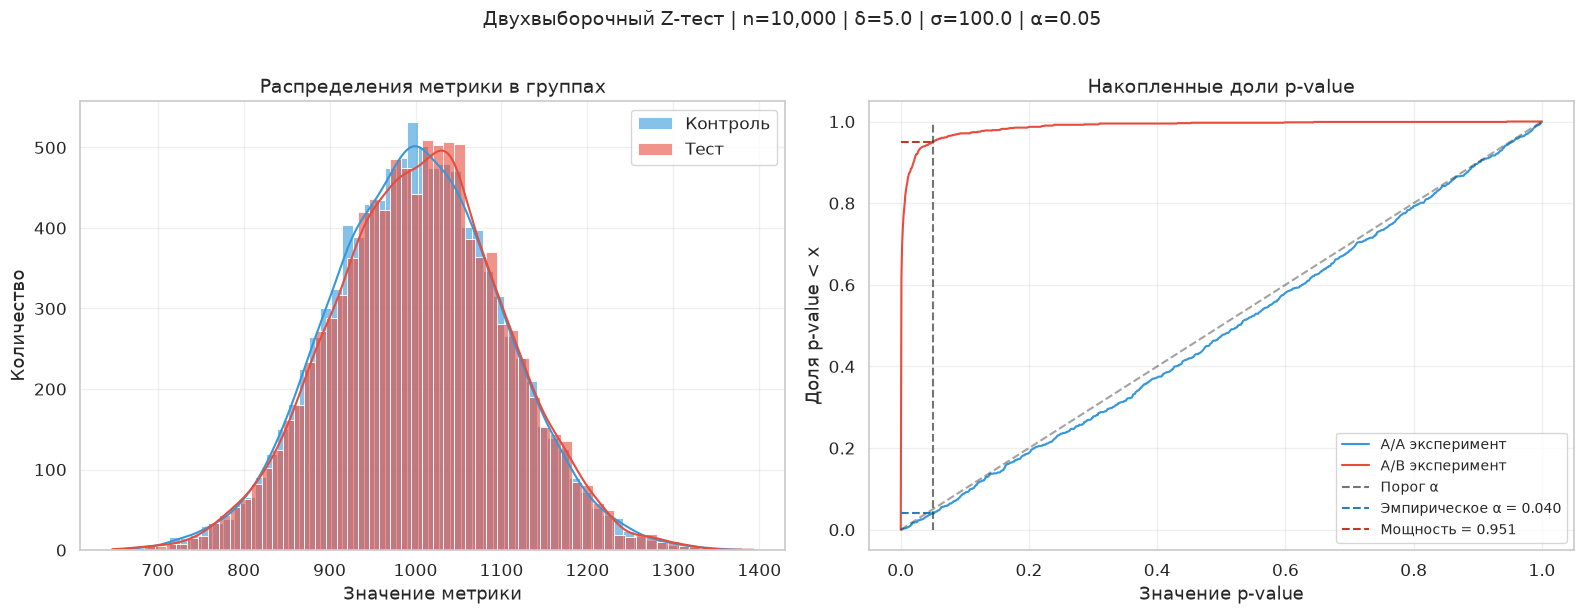

In [7]:
class ZTestResult(TypedDict):
    difference: float
    z_score: float
    p_value: float
    std_error: float


@dataclass(frozen=True)
class ZTestScenario:
    """Параметры моделирования для двухвыборочного Z-теста."""

    mu_ctrl: float
    mu_test: float
    sigma: float
    sample_size: int
    simulations: int
    alpha: float
    pop_std: Optional[float] = None
    seed: Optional[int] = None


def two_sample_z_test(control: FloatArray,
                      test: FloatArray,
                      pop_std: Optional[float] = None) -> ZTestResult:
    """
    Вычисляет статистику Z-теста для независимых выборок.
    """
    n_ctrl, n_test = len(control), len(test)
    mean_ctrl, mean_test = float(np.mean(control)), float(np.mean(test))
    diff = mean_test - mean_ctrl

    if pop_std is not None:
        std_ctrl = std_test = pop_std
    else:
        std_ctrl = float(np.std(control, ddof=1))
        std_test = float(np.std(test, ddof=1))

    std_error = np.sqrt(std_ctrl ** 2 / n_ctrl + std_test ** 2 / n_test)
    z_score = diff / std_error
    p_value = 2 * (1 - stats.norm.cdf(abs(z_score)))

    return ZTestResult(
        difference=diff,
        z_score=z_score,
        p_value=p_value,
        std_error=std_error,
    )


def generate_data(mu_ctrl: float,
                  mu_test: float,
                  sigma: float,
                  sample_size: int,
                  seed: Optional[int] = None) -> tuple[FloatArray, FloatArray]:
    """Генерирует контрольную и тестовую выборки с указанными параметрами."""
    rng = np.random.default_rng(seed)
    control = rng.normal(loc=mu_ctrl, scale=sigma, size=sample_size)
    test = rng.normal(loc=mu_test, scale=sigma, size=sample_size)
    return control, test


def run_simulation(n_sim: int,
                   sample_size: int,
                   mu_ctrl: float,
                   mu_test: float,
                   sigma: float,
                   pop_std: Optional[float] = None,
                   seed: Optional[int] = None) -> FloatArray:
    """Оценивает распределение p-value с помощью Монте-Карло."""
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sim, dtype=float)

    for i in range(n_sim):
        control = rng.normal(mu_ctrl, sigma, sample_size)
        test = rng.normal(mu_test, sigma, sample_size)
        result = two_sample_z_test(control, test, pop_std=pop_std)
        p_values[i] = result['p_value']

    return p_values


def plot_combined_distributions(control: FloatArray,
                                test: FloatArray,
                                pvalues_aa: FloatArray,
                                pvalues_ab: FloatArray,
                                alpha: float = 0.05,
                                subtitle: str = '') -> None:
    """Отрисовывает распределения метрики и соответствующих p-value."""
    fig, (ax_metrics, ax_pvalues) = plt.subplots(1, 2, figsize=(16, 6))

    sns.histplot(control, color='#3498db', alpha=0.6, kde=True, label='Контроль', ax=ax_metrics)
    sns.histplot(test, color='#e74c3c', alpha=0.6, kde=True, label='Тест', ax=ax_metrics)
    ax_metrics.set_title('Распределения метрики в группах', fontsize=14)
    ax_metrics.set_xlabel('Значение метрики')
    ax_metrics.set_ylabel('Количество')
    ax_metrics.legend()

    plot_pvalue_cdf(ax_pvalues, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value')

    plt.suptitle(subtitle, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


scenario = ZTestScenario(
    mu_ctrl=1_000,
    mu_test=1_005,
    sigma=100.0,
    sample_size=10_000,
    simulations=1_000,
    alpha=0.05,
    pop_std=100.0,
    seed=66,
)

control_sample, test_sample = generate_data(
    mu_ctrl=scenario.mu_ctrl,
    mu_test=scenario.mu_test,
    sigma=scenario.sigma,
    sample_size=scenario.sample_size,
    seed=scenario.seed,
)

pvalues_aa = run_simulation(
    n_sim=scenario.simulations,
    sample_size=scenario.sample_size,
    mu_ctrl=scenario.mu_ctrl,
    mu_test=scenario.mu_ctrl,
    sigma=scenario.sigma,
    pop_std=scenario.pop_std,
    seed=scenario.seed,
)

pvalues_ab = run_simulation(
    n_sim=scenario.simulations,
    sample_size=scenario.sample_size,
    mu_ctrl=scenario.mu_ctrl,
    mu_test=scenario.mu_test,
    sigma=scenario.sigma,
    pop_std=scenario.pop_std,
    seed=(scenario.seed + 1) if scenario.seed is not None else None,
)

subtitle_text = (
    f'Двухвыборочный Z-тест | n={scenario.sample_size:,} | '
    f'δ={scenario.mu_test - scenario.mu_ctrl:.1f} | σ={scenario.sigma:.1f} | α={scenario.alpha:.2f}'
)

plot_combined_distributions(
    control=control_sample,
    test=test_sample,
    pvalues_aa=pvalues_aa,
    pvalues_ab=pvalues_ab,
    alpha=scenario.alpha,
    subtitle=subtitle_text,
)

##### $t$-тест

$t$-тест — параметрический статистический тест, используемый для проверки гипотез о средних значениях генеральных совокупностей, когда дисперсия генеральной совокупности неизвестна. Он основан на $t$-распределении Стьюдента, которое учитывает неопределённость, вызванную оценкой дисперсии по выборке. $t$-тест особенно важен для малых выборок (n<30), но применим и для больших выборок.

**$t$-тест используется для проверки следующих гипотез**

* Сравнение выборочного среднего с гипотетическим значением генеральной совокупности $\mu_0$.
* Сравнение средних двух несвязанных групп.
* Сравнение средних измерений, полученных от одних и тех же объектов (зависимые выборки).

**Предпосылки $t$-теста**

Для корректного применения $t$-теста необходимо выполнение нескольких предпосылок:
1.  **Нормальность распределения выборочных средних**:
    *   Если исходные данные генеральной совокупности распределены нормально, то выборочные средние также будут распределены нормально.
    *   Если исходные данные не распределены нормально, но размер выборки достаточно велик (насколько — зависит от хвостов; для выручки «n > 30» не хватает, проверяйте A/A-симуляцией), то согласно **[Центральной Предельной Теореме (ЦПТ)](https://ru.wikipedia.org/wiki/Центральная_предельная_теорема)**, распределение выборочных средних будет аппроксимироваться нормальным распределением. На маленьких выборках $t$-распределение с более тяжёлыми хвостами учитывает, что дисперсия оценена по данным, но точным оно остаётся только для нормальных данных. Поэтому при малых $n$ и сильно скошенных данных $t$-тест может держать ошибку первого рода неточно.
2.  **Независимость наблюдений**:
    *   **Классический двухвыборочный $t$-тест (Student's $t$-test)** предполагает, что сравниваемые выборки независимы. Это означает, что наблюдения в одной группе не должны влиять на наблюдения в другой группе. В A/B-тестировании это обычно достигается случайным разделением пользователей из генеральной совокупности на контрольную и тестовую группы.
    *   Однако на практике встречаются **зависимые выборки**. Например, когда одна и та же группа людей измеряется до и после воздействия. В таких случаях применение стандартного двухвыборочного $t$-теста для независимых выборок может привести к некорректным результатам, так как предположение о независимости нарушается. Для зависимых выборок используется **одновыборочный $t$-тест для попарных разностей** (Paired $t$-test), который рассматривает разницу между измерениями одной и той же единицы наблюдения.
3.  **Гомогенность дисперсий**     

    *   Классический $t$-тест предполагает, что дисперсии генеральных совокупностей, из которых взяты выборки, равны.
    *   Если дисперсии генеральных совокупностей различаются, особенно при несбалансированных размерах выборок (**сплит не 50 на 50**) или **малых выборках**, применение классического $t$-теста может привести к увеличению ошибки первого рода (ложноположительных срабатываний). В таких ситуациях рекомендуется использовать **$t$-тест Уэлча (Welch's $t$-test)**, который не предполагает равенства дисперсий. Важно отметить, что для **больших выборок** и сбалансированного сплита (50 на 50) классический $t$-тест часто ведет себя корректно даже при разных дисперсиях.

**Формулировка $t$-критерия**

*   **Одновыборочный $t$-тест (сравнение среднего выборки с заданной константой)**

    $$t = \frac{\bar{X} - \mu_0}{s / \sqrt{n}}$$
    *   $\bar{X}$ — выборочное среднее.
    *   $\mu_0$ — заданное значение для сравнения.
    *   $s$ — выборочное стандартное отклонение.
    *   $n$ — размер выборки.

    Для этой статистики степени свободы $df = n-1$

*   **Двухвыборочный $t$-тест для независимых выборок (классический критерий Стьюдента при равных дисперсиях)**

    $$t = \frac{\bar{X}_1 - \bar{X}_2}{s_p \sqrt{1/n_1 + 1/n_2}}$$
    *   $\bar{X}_1$, $\bar{X}_2$ — выборочные средние двух групп.
    *   $s_p$ — объединенное стандартное отклонение.
    *   $n_1$, $n_2$ — размеры выборок.
    *   $s_p = \sqrt\frac{(n_1-1)s_1^2 + (n_2-1)s_2^2}{n_1 + n_2 - 2}$
    *   Для большого размера выборки (когда $n_1=n_2=n$) и если обе выборки из одной генеральной совокупности с $\sigma$, то знаменатель упрощается до $\sqrt{2 \sigma^2 / n}$.

    Для этой статистики степени свободы $df = n_1 + n_2 - 2$

*   **Двухвыборочный $t$-тест Уэлча (без предположения о равенстве дисперсий)**

    $$t = \frac{\bar{X}_1 - \bar{X}_2}{\sqrt{s_1^2/n_1 + s_2^2/n_2}}$$

    Степени свободы считаются по приближённой формуле Саттертуэйта:

    $$df \approx \frac{\left(s_1^2/n_1 + s_2^2/n_2\right)^2}{\frac{(s_1^2/n_1)^2}{n_1-1} + \frac{(s_2^2/n_2)^2}{n_2-1}}$$

    Тест не теряет в качестве при равных дисперсиях, поэтому в A/B-тестах его можно использовать по умолчанию.

*   **Одновыборочный $t$-тест для попарных разностей (Paired $t$-test) для зависимых выборок**

    Эта задача переформулируется. Вместо сравнения средних двух выборок, создается новая выборка попарных разностей $D_i = X_{1i} - X_{2i}$. Затем применяется одновыборочный $t$-тест к этой выборке разностей, проверяя гипотезу о том, что среднее разностей равно нулю:
    $$t = \frac{\bar{D}}{s_D / \sqrt{n}}$$
    *   $\bar{D}$ — среднее попарных разностей.
    *   $s_D$ — стандартное отклонение попарных разностей.
    *   $n$ — количество пар наблюдений.

    Для этой статистики степени свободы $df = n-1$
    
    При случайном подборе отклонение разностей будет $\sigma_D = \sqrt{2}\sigma_{\text{gen}}$. Однако при неслучайном, например, парном подборе похожих объектов, $\sigma_D$ может быть существенно меньше $\sqrt{2}\sigma_{\text{gen}}$.

**Критерии принятия решений:**

Решение, отвергать ли нулевую гипотезу, основывается на сравнении $t$-статистики с критическими значениями из распределения Стьюдента или на сравнении **p-value** с уровнем значимости $\alpha$.

1.  **Метод p-value**:
    *   **p-value** — это вероятность получить наблюдаемые или более экстремальные результаты, если нулевая гипотеза верна.
    *   Если **p-value < $\alpha$**, нулевая гипотеза отвергается. Это означает, что наблюдаемые различия статистически значимы, и мы заключаем, что эффект существует.
    *   Если **p-value $\ge \alpha$**, нулевая гипотеза не отвергается. Это означает, что наблюдаемые различия не являются статистически значимыми, и мы не можем утверждать наличие эффекта.

2.  **Метод доверительного интервала (ДИ)**:
    * Доверительный интервал уровня $1-\alpha$ строится так, что при многократном повторении эксперимента он накрывает истинное значение параметра в доле $1-\alpha$ случаев. Это свойство процедуры: для одного конкретного интервала истинное значение либо внутри него, либо нет.
    * Если значение 0 (или гипотетическая разность) **не** попадает в доверительный интервал, нулевая гипотеза отвергается. Если 0 попадает в интервал, нулевая гипотеза не отвергается.
    * Для разности средних в варианте Уэлча ДИ строится следующим образом (степени свободы $df$ по формуле Саттертуэйта):
    
$$\left(\bar{X}_1 - \bar{X}_2 \right) \pm t_{(1-\alpha/2,\,df)} \cdot \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}
$$

Сценарий для независимого t-теста


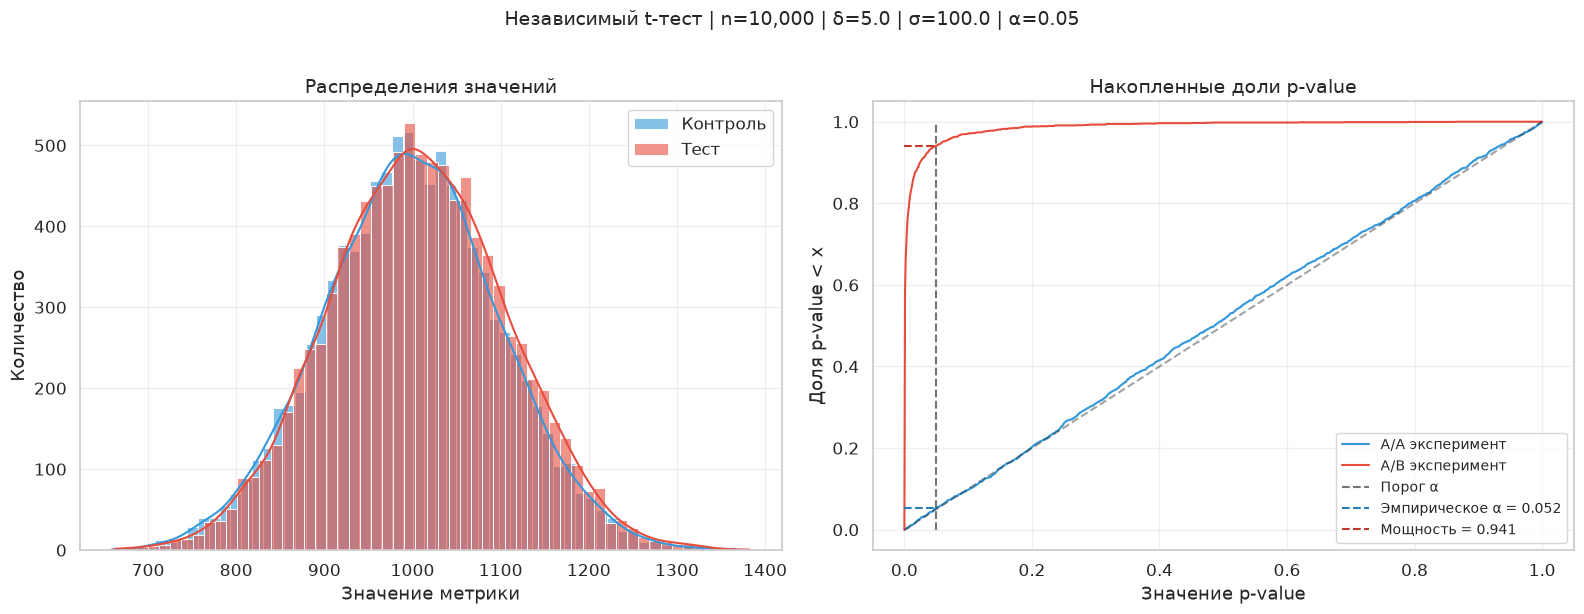


Сценарий для парного t-теста


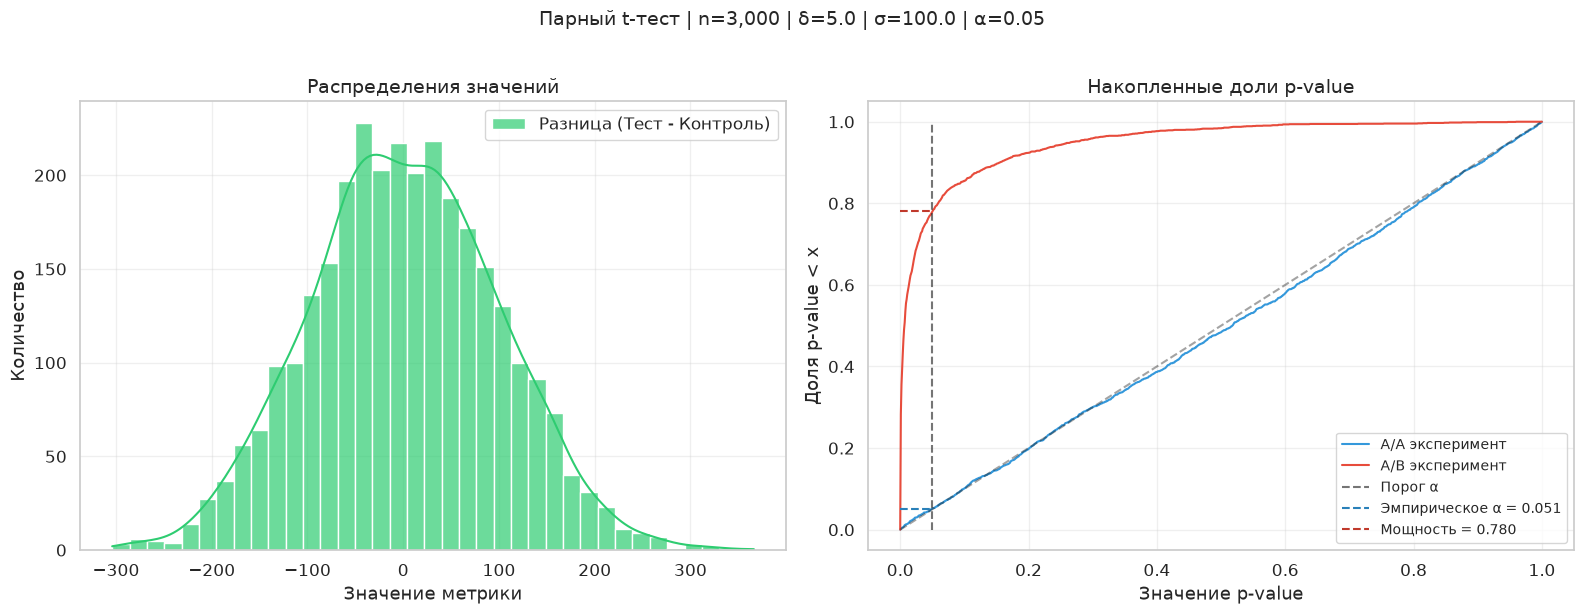

In [8]:
class TTestResult(TypedDict):
    difference: float
    t_statistic: float
    p_value: float
    mean_control: float
    mean_test: float


@dataclass(frozen=True)
class TTestScenario:
    """Параметры моделирования для t-теста."""

    mu_ctrl: float
    mu_test: float
    sigma: float
    sample_size: int
    simulations: int
    alpha: float
    paired: bool = False
    seed: Optional[int] = None


def generate_data(mu_ctrl: float,
                  mu_test: float,
                  sigma: float,
                  sample_size: int,
                  paired: bool = False,
                  correlation: float = 0.5,
                  seed: Optional[int] = None) -> tuple[FloatArray, FloatArray]:
    """
    Формирует данные для независимых или попарных наблюдений.
    """
    rng = np.random.default_rng(seed)
    if not paired:
        control = rng.normal(mu_ctrl, sigma, sample_size)
        test = rng.normal(mu_test, sigma, sample_size)
        return control, test

    # Дисперсия каждого наблюдения равна sigma², а корреляция между парами равна correlation
    shared_noise = rng.normal(0, sigma * np.sqrt(correlation), sample_size)
    residual_scale = sigma * np.sqrt(1 - correlation)
    control = mu_ctrl + shared_noise + rng.normal(0, residual_scale, sample_size)
    test = mu_test + shared_noise + rng.normal(0, residual_scale, sample_size)
    return control, test


def two_sample_t_test(control: FloatArray,
                      test: FloatArray,
                      paired: bool = False) -> TTestResult:
    """Вычисляет t-статистику (независимую или попарную)."""
    if paired:
        stat = stats.ttest_rel(control, test)
    else:
        stat = stats.ttest_ind(control, test, equal_var=False)  # тест Уэлча

    diff = float(np.mean(test) - np.mean(control))
    return TTestResult(
        difference=diff,
        t_statistic=float(stat.statistic),
        p_value=float(stat.pvalue),
        mean_control=float(np.mean(control)),
        mean_test=float(np.mean(test)),
    )


def run_simulation(n_sim: int,
                   sample_size: int,
                   mu_ctrl: float,
                   mu_test: float,
                   sigma: float,
                   paired: bool = False,
                   seed: Optional[int] = None) -> FloatArray:
    """Считает распределение p-value для заданного сценария."""
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sim)

    for i in range(n_sim):
        if paired:
            ctrl, tst = generate_data(mu_ctrl, mu_test, sigma, sample_size, paired=True, seed=rng.integers(0, 1 << 32))
        else:
            ctrl = rng.normal(mu_ctrl, sigma, sample_size)
            tst = rng.normal(mu_test, sigma, sample_size)

        res = two_sample_t_test(ctrl, tst, paired=paired)
        p_values[i] = res['p_value']

    return p_values


def plot_combined_distributions(control: FloatArray,
                                test: FloatArray,
                                pvalues_aa: FloatArray,
                                pvalues_ab: FloatArray,
                                alpha: float,
                                subtitle: str,
                                paired: bool = False) -> None:
    """Отрисовывает распределения метрик и эмпирические CDF p-value."""
    fig, (ax_metrics, ax_pvalues) = plt.subplots(1, 2, figsize=(16, 6))

    if paired:
        diff = test - control
        sns.histplot(diff, color='#2ecc71', alpha=0.7, kde=True, label='Разница (Тест - Контроль)', ax=ax_metrics)
    else:
        sns.histplot(control, color='#3498db', alpha=0.6, kde=True, label='Контроль', ax=ax_metrics)
        sns.histplot(test, color='#e74c3c', alpha=0.6, kde=True, label='Тест', ax=ax_metrics)

    ax_metrics.set_title('Распределения значений', fontsize=14)
    ax_metrics.set_xlabel('Значение метрики')
    ax_metrics.set_ylabel('Количество')
    ax_metrics.legend()

    plot_pvalue_cdf(ax_pvalues, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value')

    plt.suptitle(subtitle, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def run_full_analysis(params: TTestScenario) -> None:
    """Полный сценарий: генерация, симуляции и визуализация."""
    control, test = generate_data(
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        sample_size=params.sample_size,
        paired=params.paired,
        seed=params.seed,
    )

    pvals_aa = run_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_ctrl,
        sigma=params.sigma,
        paired=params.paired,
        seed=params.seed,
    )

    pvals_ab = run_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        paired=params.paired,
        seed=(params.seed + 1) if params.seed is not None else None,
    )

    test_type = 'Парный t-тест' if params.paired else 'Независимый t-тест'
    subtitle = (f'{test_type} | n={params.sample_size:,} | δ={params.mu_test - params.mu_ctrl:.1f} | '
                f'σ={params.sigma:.1f} | α={params.alpha:.2f}')

    plot_combined_distributions(
        control=control,
        test=test,
        pvalues_aa=pvals_aa,
        pvalues_ab=pvals_ab,
        alpha=params.alpha,
        subtitle=subtitle,
        paired=params.paired,
    )


independent_scenario = TTestScenario(
    mu_ctrl=1_000,
    mu_test=1_005,
    sigma=100.0,
    sample_size=10_000,
    simulations=2_000,
    alpha=0.05,
    paired=False,
    seed=666,
)

paired_scenario = TTestScenario(
    mu_ctrl=1_000,
    mu_test=1_005,
    sigma=100.0,
    sample_size=3_000,
    simulations=2_000,
    alpha=0.05,
    paired=True,
    seed=666,
)

print('Сценарий для независимого t-теста')
run_full_analysis(independent_scenario)

print('\nСценарий для парного t-теста')
run_full_analysis(paired_scenario)

#### Непараметрические тесты

##### $\chi^2$-тест

χ²-тест — это непараметрический статистический тест, который используется для анализа категориальных данных.

В зависимости от задачи различают два основных вида χ²-теста:
* **«Goodness-of-Fit» test (тест согласия)** — проверка, насколько распределение наблюдаемых частот соответствует теоретическому распределению.
* **Independence test (тест независимости)** — проверка взаимосвязи (независимости) двух категориальных признаков в таблице сопряжённости (contingency table).

В A/B-тестах чаще всего встречается второй вариант: строки — варианты исхода, столбцы — группы. Для конверсии (таблица 2×2) он эквивалентен двустороннему $z$-тесту для долей: $\chi^2 = z^2$.

**Предпосылки χ²-теста**  

* Независимость наблюдений: каждая единица выборки входит в таблицу только один раз.
* Адекватный объём выборки и ожидаемые частоты: в ячейках таблицы не должно быть слишком малых ожиданий (обычно $E_i \ge 5$).
* Категории взаимоисключающие и исчерпывающие: каждая наблюдаемая единица попадает ровно в одну категорию.

**Формулировки χ² критериев**

1. **Тест согласия (Goodness-of-Fit)**

    * **Нулевая гипотеза ($H_0$):**  наблюдаемое распределение совпадает с теоретическим (или с заданным распределением)

    * **Альтернативная гипотеза ($H_1$):** наблюдаемое распределение отличается от теоретического  

    * Статистика:

$$\chi^2 = \sum_{i=1}^k \frac{(O_i - E_i)^2}{E_i}$$

  * $O_i$— наблюдаемая частота в $i$-й категории,
  * $E_i$ — ожидаемая теоретическая частота в $i$-й категории,
  * $k$ — число категорий.  

Степени свободы: $df=k−1−m$, где $m$ — число оцененных на основе данных параметров (если параметры распределения не фиксированы заранее).

2. **Тест независимости**

    Рассматриваем таблицу размера $r \times c$ (строки — категории одного фактора, столбцы — другого).

    * **Нулевая гипотеза ($H_0$):**  два признака независимы: $P(\text{row}_i, \text{col}_j) = P(\text{row}_i) \times P(\text{col}_j)$  

    * **Альтернативная гипотеза ($H_1$):** признаки зависимы: $P(\text{row}_i, \text{col}_j) \neq P(\text{row}_i) \times P(\text{col}_j)$  

    * Статистика:
$$\chi^2 =
\displaystyle \sum_{i=1}^r \sum_{j=1}^c \frac{(O_{ij} - E_{ij})^2}{E_{ij}}
$$

Степени свободы: $df=(r−1) (c−1)$

**Критерий принятия решения**

Решение, отвергать ли нулевую гипотезу, основывается на сравнении $\chi^2$-статистики с критическими значениями из распределения $\chi^2$ или на сравнении p-value с уровнем значимости $\alpha$.

Метод p-value:

* p-value — это вероятность получить наблюдаемые или более экстремальные результаты, если нулевая гипотеза верна.
* Если p-value <  α , нулевая гипотеза отвергается. Это означает, что наблюдаемые различия статистически значимы, и мы заключаем, что эффект существует.
* Если p-value  ≥α , нулевая гипотеза не отвергается. Это означает, что наблюдаемые различия не являются статистически значимыми, и мы не можем утверждать наличие эффекта.

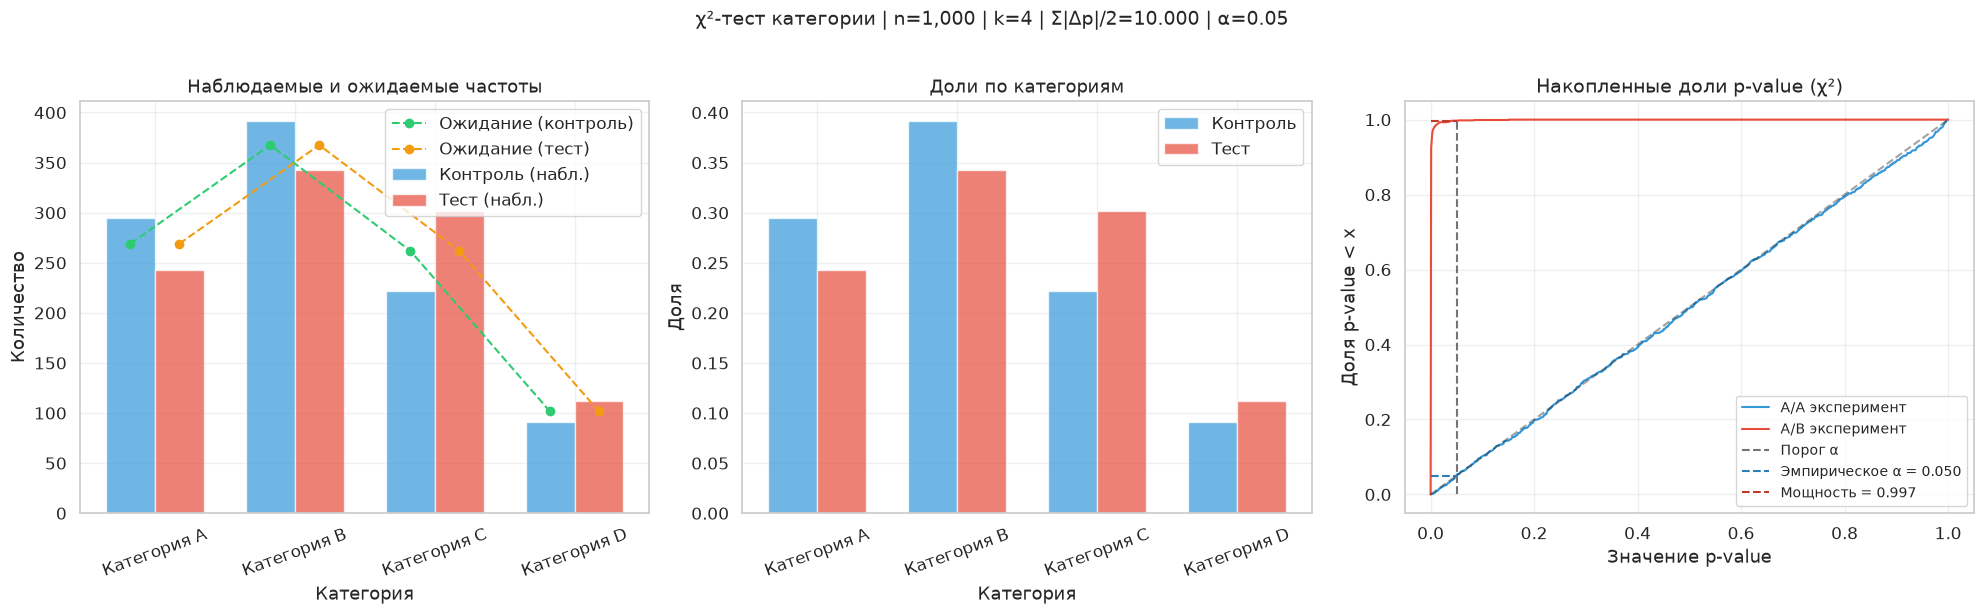

In [9]:
MatrixInt = NDArray[np.int64]


class ChiSquareResult(TypedDict):
    chi2_statistic: float
    p_value: float
    degrees_of_freedom: int
    expected_frequencies: FloatArray


@dataclass(frozen=True)
class ChiSquareScenario:
    """Параметры моделирования для χ²-теста независимости."""

    probabilities_ctrl: Sequence[float]
    probabilities_test: Sequence[float]
    sample_size: int
    simulations: int
    alpha: float
    seed: Optional[int] = None


def chi2_test(observed: MatrixInt) -> ChiSquareResult:
    """
    Выполняет χ²-тест на независимость категориальных распределений.
    """
    chi2, p_value, dof, expected = stats.chi2_contingency(observed)
    return ChiSquareResult(
        chi2_statistic=float(chi2),
        p_value=float(p_value),
        degrees_of_freedom=int(dof),
        expected_frequencies=expected,
    )


def generate_contingency_table(n_samples: int,
                               p_ctrl: Sequence[float],
                               p_test: Sequence[float],
                               seed: Optional[int] = None) -> MatrixInt:
    """Создаёт таблицу сопряжённости для двух групп."""
    rng = np.random.default_rng(seed)
    ctrl = rng.multinomial(n_samples, np.asarray(p_ctrl) / np.sum(p_ctrl))
    test = rng.multinomial(n_samples, np.asarray(p_test) / np.sum(p_test))
    return np.vstack([ctrl, test]).T


def run_chi2_simulation(n_sim: int,
                        n_samples: int,
                        p_ctrl: Sequence[float],
                        p_test: Sequence[float],
                        seed: Optional[int] = None) -> FloatArray:
    """Возвращает массив p-value из Монте-Карло для χ²-теста."""
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sim)
    p_ctrl = np.asarray(p_ctrl, dtype=float)
    p_test = np.asarray(p_test, dtype=float)

    for i in range(n_sim):
        ctrl = rng.multinomial(n_samples, p_ctrl / np.sum(p_ctrl))
        test = rng.multinomial(n_samples, p_test / np.sum(p_test))
        observed = np.vstack([ctrl, test]).T
        res = chi2_test(observed)
        p_values[i] = res['p_value']

    return p_values


def plot_chi2_results(observed: MatrixInt,
                      expected: FloatArray,
                      pvalues_aa: FloatArray,
                      pvalues_ab: FloatArray,
                      alpha: float,
                      subtitle: str,
                      categories: Optional[List[str]] = None) -> None:
    """Отрисовывает таблицу, относительные частоты и распределение p-value."""
    if categories is None:
        categories = [f'Категория {i + 1}' for i in range(observed.shape[0])]

    fig, (ax_counts, ax_relative, ax_pvalues) = plt.subplots(1, 3, figsize=(20, 6))
    x = np.arange(len(categories))
    width = 0.35

    ax_counts.bar(x - width / 2, observed[:, 0], width, label='Контроль (набл.)', color='#3498db', alpha=0.7)
    ax_counts.bar(x + width / 2, observed[:, 1], width, label='Тест (набл.)', color='#e74c3c', alpha=0.7)
    ax_counts.plot(x - width / 2, expected[:, 0], 'o--', color='#2ecc71', label='Ожидание (контроль)')
    ax_counts.plot(x + width / 2, expected[:, 1], 'o--', color='#f39c12', label='Ожидание (тест)')
    ax_counts.set_title('Наблюдаемые и ожидаемые частоты')
    ax_counts.set_xlabel('Категория')
    ax_counts.set_ylabel('Количество')
    ax_counts.set_xticks(x, categories, rotation=20)
    ax_counts.legend()

    rel_ctrl = observed[:, 0] / np.sum(observed[:, 0])
    rel_test = observed[:, 1] / np.sum(observed[:, 1])
    ax_relative.bar(x - width / 2, rel_ctrl, width, label='Контроль', color='#3498db', alpha=0.7)
    ax_relative.bar(x + width / 2, rel_test, width, label='Тест', color='#e74c3c', alpha=0.7)
    ax_relative.set_title('Доли по категориям')
    ax_relative.set_xlabel('Категория')
    ax_relative.set_ylabel('Доля')
    ax_relative.set_xticks(x, categories, rotation=20)
    ax_relative.legend()

    plot_pvalue_cdf(ax_pvalues, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value (χ²)')

    plt.suptitle(subtitle, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def run_chi2_analysis(params: ChiSquareScenario, categories: Optional[List[str]] = None) -> None:
    """Полный анализ: генерация таблицы, симуляции и визуализация."""
    observed = generate_contingency_table(
        n_samples=params.sample_size,
        p_ctrl=params.probabilities_ctrl,
        p_test=params.probabilities_test,
        seed=params.seed,
    )
    expected = chi2_test(observed)['expected_frequencies']

    pvals_aa = run_chi2_simulation(
        n_sim=params.simulations,
        n_samples=params.sample_size,
        p_ctrl=params.probabilities_ctrl,
        p_test=params.probabilities_ctrl,
        seed=params.seed,
    )

    pvals_ab = run_chi2_simulation(
        n_sim=params.simulations,
        n_samples=params.sample_size,
        p_ctrl=params.probabilities_ctrl,
        p_test=params.probabilities_test,
        seed=(params.seed + 1) if params.seed is not None else None,
    )

    effect = np.sum(np.abs(np.array(params.probabilities_test) - np.array(params.probabilities_ctrl))) / 2
    subtitle = (f'χ²-тест категории | n={params.sample_size:,} | k={len(params.probabilities_ctrl)} | '
                f'Σ|Δp|/2={effect:.3f} | α={params.alpha:.2f}')

    plot_chi2_results(
        observed=observed,
        expected=expected,
        pvalues_aa=pvals_aa,
        pvalues_ab=pvals_ab,
        alpha=params.alpha,
        subtitle=subtitle,
        categories=categories,
    )


scenario = ChiSquareScenario(
    probabilities_ctrl=[30, 40, 20, 10],
    probabilities_test=[25, 35, 30, 10],
    sample_size=1_000,
    simulations=1_000,
    alpha=0.05,
    seed=42,
)

category_labels = ['Категория A', 'Категория B', 'Категория C', 'Категория D']
run_chi2_analysis(scenario, categories=category_labels)

##### Mann–Whitney $U$ test

$U$-тест (тест Манна–Уитни) — это непараметрический критерий для сравнения двух независимых выборок. Он не требует нормальности данных и основан на ранжировании объединённой выборки.

$U$-тест Манна–Уитни применяют, когда необходимо проверить, что значения одной группы склонны быть больше значений другой. **Его нельзя использовать для проверки равенства средних или медиан** (подробно рассматривается [тут](https://habr.com/ru/companies/avito/articles/709596/)): значимый результат возможен и при равных средних.

**Предпосылки $U$-теста**  

* Независимость наблюдений внутри и между группами.
* Сравнивать медианы можно только при дополнительном предположении, что распределения отличаются лишь сдвигом и имеют одинаковую форму.
* Минимум порядкового уровня: достаточно уметь упорядочить (ранжировать) все наблюдения.

**Формулировки U-теста**

* **Нулевая гипотеза ($H_0$):** значения групп стохастически не различаются: $P(T > C) + \frac{1}{2}P(T = C) = \frac{1}{2}$. Часто её записывают более сильно: распределения совпадают, $F_T = F_C$.

* **Альтернативная гипотеза ($H_1$):** значения одной из групп склонны быть больше: $P(T > C) + \frac{1}{2}P(T = C) \neq \frac{1}{2}$.

* **$U$-статистика** считает, сколько пар «тест-контроль» упорядочены в пользу теста (совпадения считаются с весом 1/2):

$$
U = \sum_{i=1}^{N_T} \sum_{j=1}^{N_C} \left( \mathbf{1}\left[ T_i > C_j \right] + \tfrac{1}{2}\mathbf{1}\left[ T_i = C_j \right] \right)
$$

**Критерий принятия решения**

Решение, отвергать ли нулевую гипотезу, основывается на сравнении $U$-статистики с критическими значениями распределения статистики при верной $H_0$ (при больших выборках она приближается нормальным распределением) или на сравнении **p-value** с уровнем значимости $\alpha$.

**Метод p-value**:

  *   **p-value** — это вероятность получить наблюдаемые или более экстремальные результаты, если нулевая гипотеза верна.
  *   Если **p-value < $\alpha$**, нулевая гипотеза отвергается. Это означает, что наблюдаемые различия статистически значимы, и мы заключаем, что эффект существует.
  *   Если **p-value $\ge \alpha$**, нулевая гипотеза не отвергается. Это означает, что наблюдаемые различия не являются статистически значимыми, и мы не можем утверждать наличие эффекта.

Сценарий для нормального распределения:


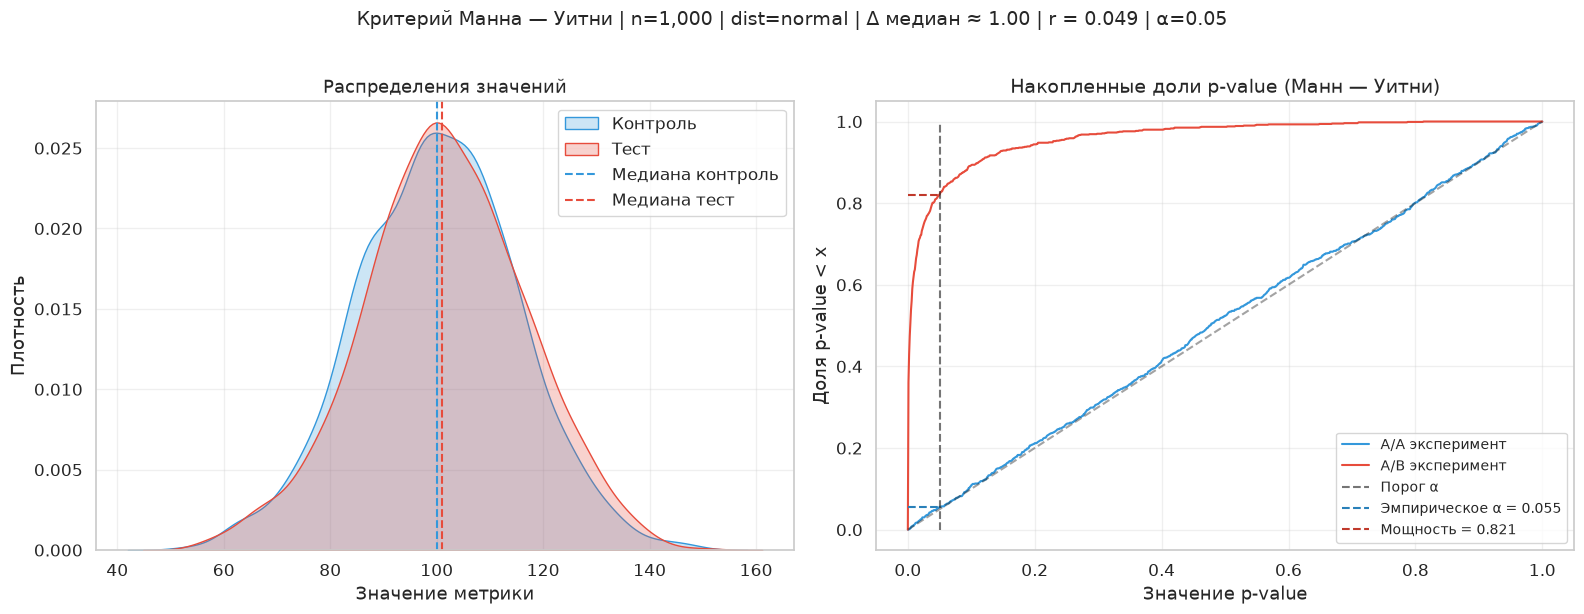


Сценарий для экспоненциального распределения:


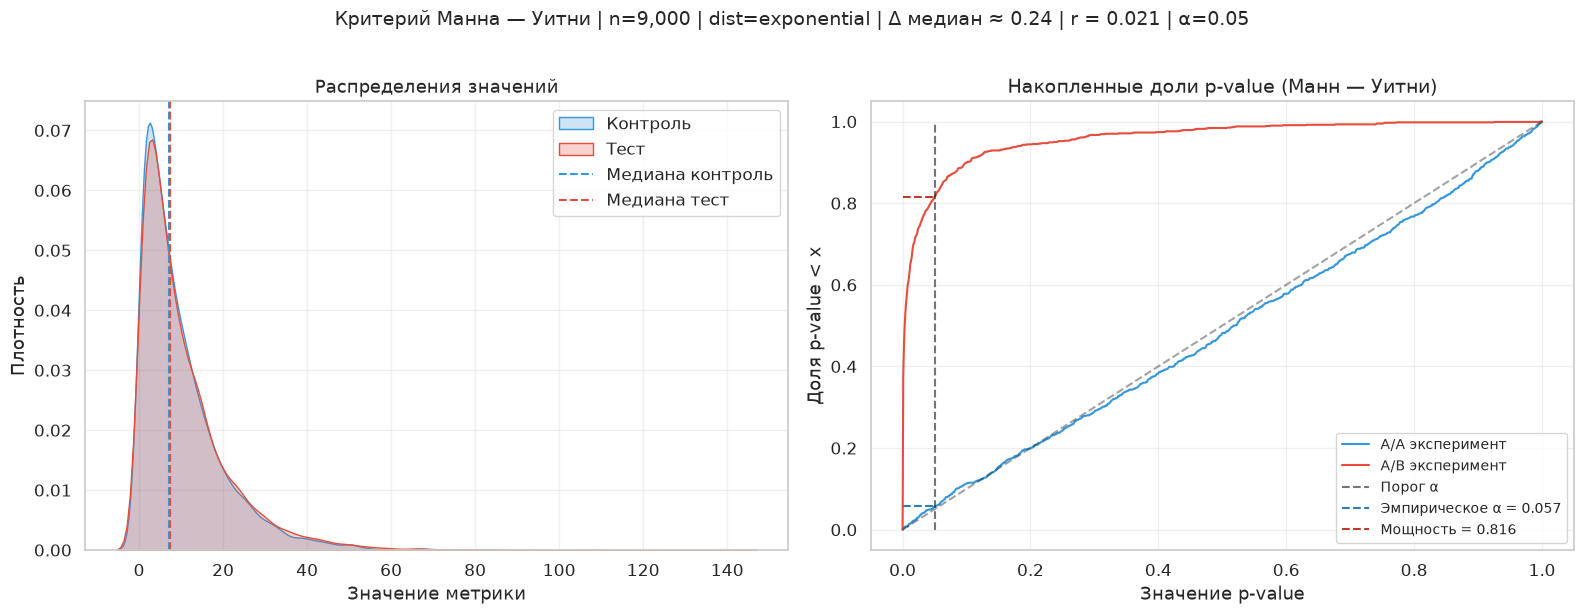

In [10]:
DistributionName = Literal['normal', 'exponential']


class MannWhitneyResult(TypedDict):
    u_statistic: float
    p_value: float
    effect_size: float
    median_control: float
    median_test: float


@dataclass(frozen=True)
class MannWhitneyScenario:
    """Параметры моделирования для критерия Манна — Уитни."""

    mu_ctrl: float
    mu_test: float
    sigma: float
    sample_size: int
    simulations: int
    alpha: float
    distribution: DistributionName = 'normal'
    seed: Optional[int] = None


def mann_whitney_u_test(control: FloatArray, test: FloatArray) -> MannWhitneyResult:
    """Возвращает статистику U, p-value, ранговую бисериальную корреляцию и медианы."""
    u_stat, p_value = stats.mannwhitneyu(control, test, alternative='two-sided')
    n_ctrl, n_test = len(control), len(test)
    effect_size = 1 - (2 * u_stat) / (n_ctrl * n_test)

    return MannWhitneyResult(
        u_statistic=float(u_stat),
        p_value=float(p_value),
        effect_size=float(effect_size),
        median_control=float(np.median(control)),
        median_test=float(np.median(test)),
    )


def generate_data(mu_ctrl: float,
                  mu_test: float,
                  sigma: float,
                  sample_size: int,
                  dist: DistributionName = 'normal',
                  seed: Optional[int] = None) -> tuple[FloatArray, FloatArray]:
    """Генерирует данные для выбранного распределения."""
    rng = np.random.default_rng(seed)

    if dist == 'normal':
        control = rng.normal(loc=mu_ctrl, scale=sigma, size=sample_size)
        test = rng.normal(loc=mu_test, scale=sigma, size=sample_size)
    elif dist == 'exponential':
        control = rng.exponential(scale=mu_ctrl, size=sample_size)
        test = rng.exponential(scale=mu_test, size=sample_size)
    else:
        raise ValueError('Поддерживаются только normal и exponential')

    return control, test


def run_u_test_simulation(n_sim: int,
                          sample_size: int,
                          mu_ctrl: float,
                          mu_test: float,
                          sigma: float,
                          dist: DistributionName = 'normal',
                          seed: Optional[int] = None) -> FloatArray:
    """Формирует распределение p-value для U-теста."""
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sim)

    for i in range(n_sim):
        if dist == 'normal':
            ctrl = rng.normal(mu_ctrl, sigma, sample_size)
            test = rng.normal(mu_test, sigma, sample_size)
        else:
            ctrl = rng.exponential(mu_ctrl, sample_size)
            test = rng.exponential(mu_test, sample_size)

        res = mann_whitney_u_test(ctrl, test)
        p_values[i] = res['p_value']

    return p_values


def plot_u_test_results(control: FloatArray,
                        test: FloatArray,
                        pvalues_aa: FloatArray,
                        pvalues_ab: FloatArray,
                        alpha: float,
                        subtitle: str) -> None:
    """Краткое визуальное резюме для критерия Манна — Уитни."""
    fig, (ax_kde, ax_pvalues) = plt.subplots(1, 2, figsize=(16, 6))

    sns.kdeplot(control, color='#3498db', label='Контроль', ax=ax_kde, fill=True)
    sns.kdeplot(test, color='#e74c3c', label='Тест', ax=ax_kde, fill=True)
    ax_kde.axvline(np.median(control), color='#3498db', linestyle='--', label='Медиана контроль')
    ax_kde.axvline(np.median(test), color='#e74c3c', linestyle='--', label='Медиана тест')
    ax_kde.set_title('Распределения значений')
    ax_kde.set_xlabel('Значение метрики')
    ax_kde.set_ylabel('Плотность')
    ax_kde.legend()

    plot_pvalue_cdf(ax_pvalues, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value (Манн — Уитни)')

    plt.suptitle(subtitle, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def run_full_u_test_analysis(params: MannWhitneyScenario) -> None:
    """Выполняет полный сценарий анализа для U-теста."""
    control, test = generate_data(
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        sample_size=params.sample_size,
        dist=params.distribution,
        seed=params.seed,
    )

    test_result = mann_whitney_u_test(control, test)

    pvals_aa = run_u_test_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_ctrl,
        sigma=params.sigma,
        dist=params.distribution,
        seed=params.seed,
    )

    pvals_ab = run_u_test_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        dist=params.distribution,
        seed=(params.seed + 1) if params.seed is not None else None,
    )

    subtitle = (
        f'Критерий Манна — Уитни | n={params.sample_size:,} | dist={params.distribution} | '
        f'Δ медиан ≈ {test_result["median_test"] - test_result["median_control"]:.2f} | '
        f'r = {test_result["effect_size"]:.3f} | α={params.alpha:.2f}'
    )

    plot_u_test_results(
        control=control,
        test=test,
        pvalues_aa=pvals_aa,
        pvalues_ab=pvals_ab,
        alpha=params.alpha,
        subtitle=subtitle,
    )


scenario_normal = MannWhitneyScenario(
    mu_ctrl=100.0,
    mu_test=102.0,
    sigma=15.0,
    sample_size=1_000,
    simulations=1_000,
    alpha=0.05,
    distribution='normal',
    seed=666,
)

scenario_exponential = MannWhitneyScenario(
    mu_ctrl=10.0,
    mu_test=10.5,
    sigma=0.0,
    sample_size=9_000,
    simulations=1_000,
    alpha=0.05,
    distribution='exponential',
    seed=666,
)

print('Сценарий для нормального распределения:')
run_full_u_test_analysis(scenario_normal)

print('\nСценарий для экспоненциального распределения:')
run_full_u_test_analysis(scenario_exponential)

##### Бутстреп

Для метрик без готового критерия подходит бутстреп. Он почти универсален, но не всемогущ: например, он плохо работает для экстремальных статистик и при очень тяжёлых хвостах.

Общий пайплайн:

* Много раз:
  1. Делаем подвыборки с возвращением.
  2. Считаем метрики из полученных выборок.

* На основе полученных статистик делаем вывод, отвергать ли гипотезу.

Способ получить p-value бутстрепом описан способ получить p-value: перед ресэмплированием группы сдвигаются к общему среднему, чтобы выполнялась $H_0$. Просто объединять группы нельзя: так проверяется равенство всего распределения, а не средних, и при разных дисперсиях ошибка первого рода сильно растёт.

=== Сценарий для нормального распределения ===


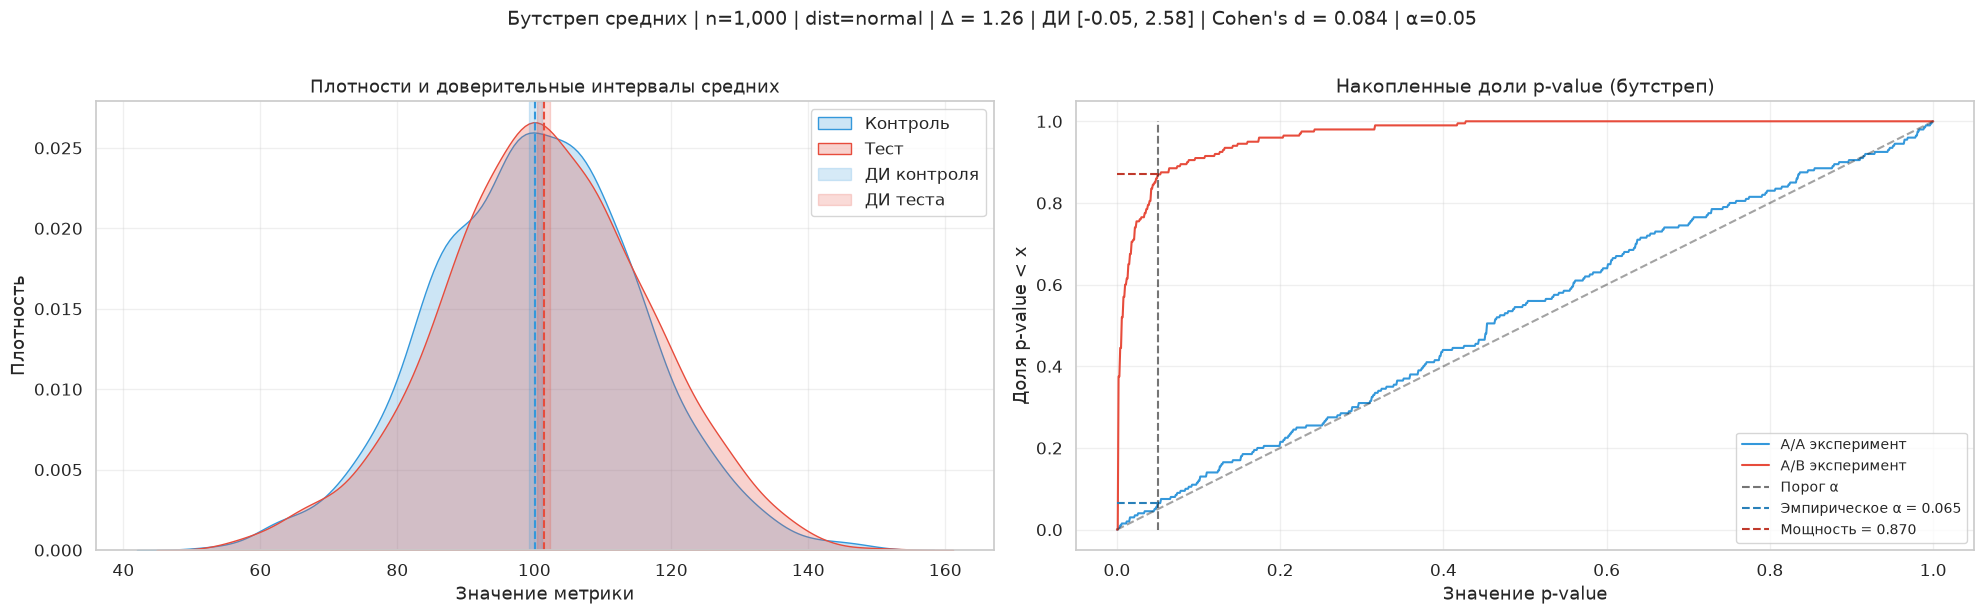


=== Сценарий для экспоненциального распределения ===


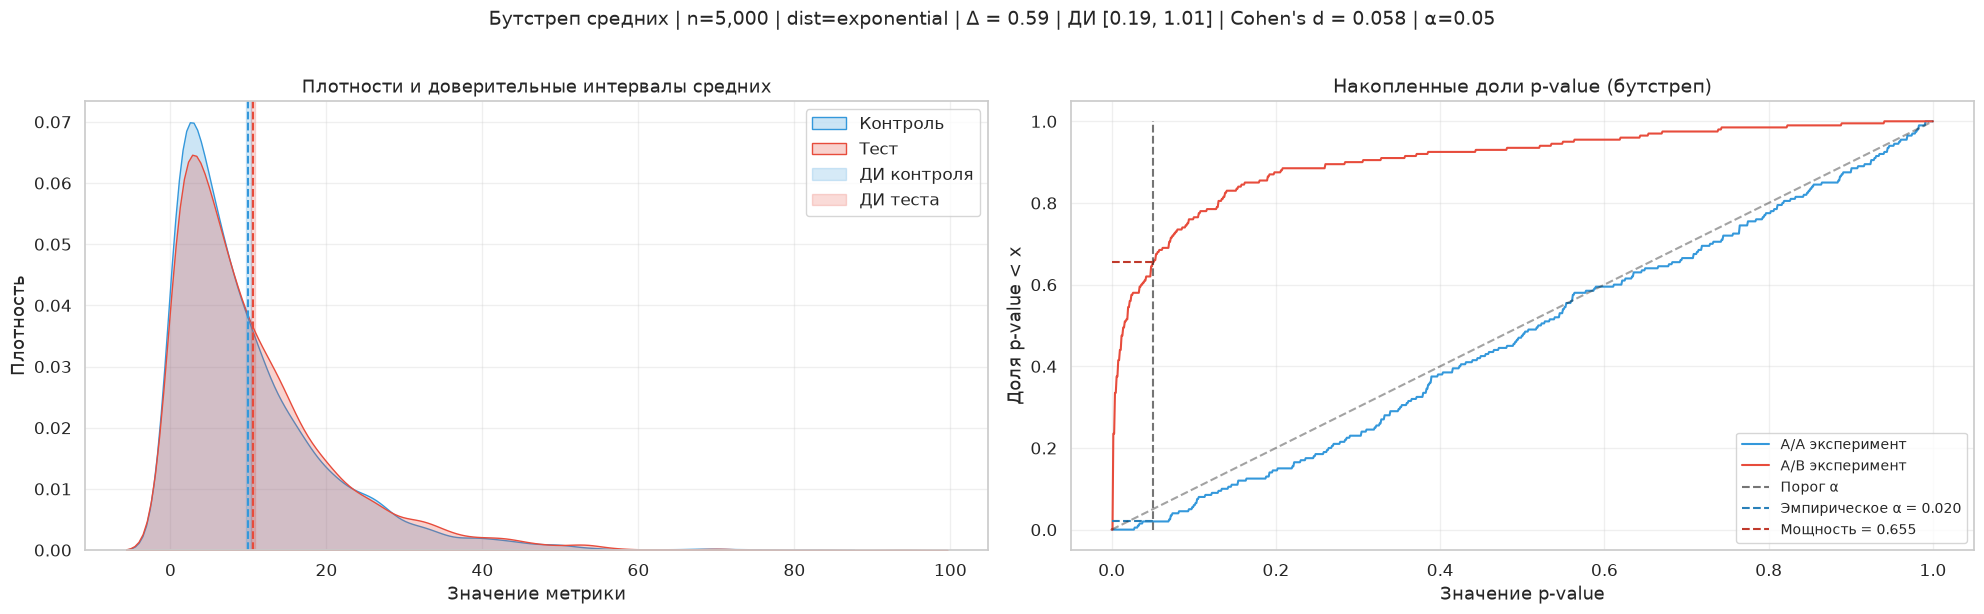

In [11]:
DistributionName = Literal['normal', 'exponential', 'uniform']


class BootstrapResult(TypedDict):
    difference: float
    ci_lower: float
    ci_upper: float
    p_value: float
    mean_control: float
    mean_test: float
    n_resamples: int


@dataclass(frozen=True)
class BootstrapScenario:
    """Параметры моделирования для бутстрепа средних."""

    mu_ctrl: float
    mu_test: float
    sigma: float
    sample_size: int
    simulations: int
    n_resamples: int
    alpha: float
    distribution: DistributionName = 'normal'
    seed: Optional[int] = None


def bootstrap_compare_means(control: FloatArray,
                            test: FloatArray,
                            n_resamples: int = 2_000,
                            confidence_level: float = 0.95,
                            seed: Optional[int] = None) -> BootstrapResult:
    """Оценивает разность средних: перцентильный бутстреп-ДИ и двусторонний p-value."""
    rng = np.random.default_rng(seed)
    n_ctrl, n_test = len(control), len(test)
    mean_ctrl, mean_test = float(np.mean(control)), float(np.mean(test))
    observed_diff = mean_test - mean_ctrl

    def resampled_means(data: FloatArray) -> FloatArray:
        # Матрица из n_resamples выборок: одна строка — одна бутстреп-выборка
        return data[rng.integers(0, len(data), (n_resamples, len(data)))].mean(axis=1)

    # Доверительный интервал: ресэмплируем исходные группы
    diffs = resampled_means(test) - resampled_means(control)
    alpha = 1 - confidence_level
    ci_lower, ci_upper = np.quantile(diffs, [alpha / 2, 1 - alpha / 2])

    # P-value: сдвигаем группы к общему среднему, чтобы выполнялась H₀
    pooled_mean = (n_ctrl * mean_ctrl + n_test * mean_test) / (n_ctrl + n_test)
    diffs_null = resampled_means(test - mean_test + pooled_mean) - resampled_means(control - mean_ctrl + pooled_mean)
    p_value = float((np.sum(np.abs(diffs_null) >= abs(observed_diff)) + 1) / (n_resamples + 1))

    return BootstrapResult(
        difference=observed_diff,
        ci_lower=float(ci_lower),
        ci_upper=float(ci_upper),
        p_value=p_value,
        mean_control=mean_ctrl,
        mean_test=mean_test,
        n_resamples=n_resamples,
    )


def generate_data(mu_ctrl: float,
                  mu_test: float,
                  sigma: float,
                  sample_size: int,
                  dist: DistributionName = 'normal',
                  seed: Optional[int] = None) -> tuple[FloatArray, FloatArray]:
    """Создаёт данные для выбранного распределения."""
    rng = np.random.default_rng(seed)

    if dist == 'normal':
        control = rng.normal(mu_ctrl, sigma, sample_size)
        test = rng.normal(mu_test, sigma, sample_size)
    elif dist == 'exponential':
        control = rng.exponential(mu_ctrl, sample_size)
        test = rng.exponential(mu_test, sample_size)
    elif dist == 'uniform':
        control = rng.uniform(mu_ctrl, mu_ctrl + sigma, sample_size)
        test = rng.uniform(mu_test, mu_test + sigma, sample_size)
    else:
        raise ValueError('Поддерживаются распределения normal/exponential/uniform')

    return control, test


def run_bootstrap_simulation(n_sim: int,
                             sample_size: int,
                             mu_ctrl: float,
                             mu_test: float,
                             sigma: float,
                             n_resamples: int,
                             dist: DistributionName = 'normal',
                             seed: Optional[int] = None) -> FloatArray:
    """Возвращает массив p-value из бутстреп-теста."""
    rng = np.random.default_rng(seed)
    p_values = np.empty(n_sim)

    for i in range(n_sim):
        control, test = generate_data(
            mu_ctrl=mu_ctrl,
            mu_test=mu_test,
            sigma=sigma,
            sample_size=sample_size,
            dist=dist,
            seed=rng.integers(0, 1 << 32),
        )
        res = bootstrap_compare_means(control, test, n_resamples=n_resamples, seed=rng.integers(0, 1 << 32))
        p_values[i] = res['p_value']

    return p_values


def plot_bootstrap_results(control: FloatArray,
                           test: FloatArray,
                           pvalues_aa: FloatArray,
                           pvalues_ab: FloatArray,
                           alpha: float,
                           subtitle: str) -> None:
    """Комбинированная визуализация распределений и p-value."""
    fig, (ax_dist, ax_pvalues) = plt.subplots(1, 2, figsize=(20, 6))

    sns.kdeplot(control, color='#3498db', label='Контроль', ax=ax_dist, fill=True)
    sns.kdeplot(test, color='#e74c3c', label='Тест', ax=ax_dist, fill=True)

    def _mean_ci(data: FloatArray) -> tuple[float, float, float]:
        half_width = 1.96 * np.std(data, ddof=1) / np.sqrt(len(data))
        return float(np.mean(data)), float(np.mean(data) - half_width), float(np.mean(data) + half_width)

    mean_ctrl, ci_ctrl_low, ci_ctrl_high = _mean_ci(control)
    mean_test, ci_test_low, ci_test_high = _mean_ci(test)

    ax_dist.axvspan(ci_ctrl_low, ci_ctrl_high, color='#3498db', alpha=0.2, label='ДИ контроля')
    ax_dist.axvspan(ci_test_low, ci_test_high, color='#e74c3c', alpha=0.2, label='ДИ теста')
    ax_dist.axvline(mean_ctrl, color='#3498db', linestyle='--')
    ax_dist.axvline(mean_test, color='#e74c3c', linestyle='--')
    ax_dist.set_title('Плотности и доверительные интервалы средних')
    ax_dist.set_xlabel('Значение метрики')
    ax_dist.set_ylabel('Плотность')
    ax_dist.legend()

    plot_pvalue_cdf(ax_pvalues, pvalues_aa, pvalues_ab, alpha, 'Накопленные доли p-value (бутстреп)')

    plt.suptitle(subtitle, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


def run_full_bootstrap_analysis(params: BootstrapScenario) -> None:
    """Полный сценарий для бутстрепа средних."""
    control, test = generate_data(
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        sample_size=params.sample_size,
        dist=params.distribution,
        seed=params.seed,
    )

    summary = bootstrap_compare_means(
        control,
        test,
        n_resamples=params.n_resamples,
        confidence_level=1 - params.alpha,
        seed=params.seed,
    )

    pvals_aa = run_bootstrap_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_ctrl,
        sigma=params.sigma,
        n_resamples=params.n_resamples,
        dist=params.distribution,
        seed=params.seed,
    )

    pvals_ab = run_bootstrap_simulation(
        n_sim=params.simulations,
        sample_size=params.sample_size,
        mu_ctrl=params.mu_ctrl,
        mu_test=params.mu_test,
        sigma=params.sigma,
        n_resamples=params.n_resamples,
        dist=params.distribution,
        seed=(params.seed + 1) if params.seed is not None else None,
    )

    pooled_std = np.sqrt((np.var(control) + np.var(test)) / 2)
    effect_size = summary['difference'] / pooled_std if pooled_std else 0.0
    subtitle = (
        f'Бутстреп средних | n={params.sample_size:,} | dist={params.distribution} | '
        f'Δ = {summary["difference"]:.2f} | ДИ [{summary["ci_lower"]:.2f}, {summary["ci_upper"]:.2f}] | '
        f"Cohen's d = {effect_size:.3f} | α={params.alpha:.2f}"
    )

    plot_bootstrap_results(
        control=control,
        test=test,
        pvalues_aa=pvals_aa,
        pvalues_ab=pvals_ab,
        alpha=params.alpha,
        subtitle=subtitle,
    )


scenario_normal = BootstrapScenario(
    mu_ctrl=100.0,
    mu_test=102.0,
    sigma=15.0,
    sample_size=1_000,
    simulations=200,
    n_resamples=500,
    alpha=0.05,
    distribution='normal',
    seed=666,
)

scenario_exponential = BootstrapScenario(
    mu_ctrl=10.0,
    mu_test=10.5,
    sigma=0.0,
    sample_size=5_000,
    simulations=200,
    n_resamples=500,
    alpha=0.05,
    distribution='exponential',
    seed=666,
)

print('=== Сценарий для нормального распределения ===')
run_full_bootstrap_analysis(scenario_normal)

print('\n=== Сценарий для экспоненциального распределения ===')
run_full_bootstrap_analysis(scenario_exponential)

## Часть 2. Что мерить: метрики

План есть — теперь решаем, какие метрики играют какие роли и в каком порядке читать результат.


## Виды метрик и как их тестируем

Сначала роли метрик и порядок чтения результата, затем — как каждую роль тестируем с точки зрения поправок.


### Сквозной кейс и роли метрик

Все примеры занятия живут в одном продукте: приложении доставки еды. Главная цель бизнеса — чтобы пользователи заказывали больше и дольше оставались. Мы формулируем её как **долгосрочную метрику (north star)**: число заказов на пользователя за 28 дней. Проблема в том, что узнать её можно только через четыре недели, а тест нужно закончить раньше. Поэтому в тесте мы смотрим не на одну метрику, а на несколько, и у каждой своя роль.

Роли удобно разделять по тому, **что мы с метрикой делаем**. Эта классификация из статьи Microsoft ([Dmitriev и др., 2017](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf)) дополняет классическое разбиение success/guardrail/deterioration/quality: она отвечает на вопрос «в каком порядке читать результат», а не «как считать поправки».

* **Метрики качества данных.** Первый вопрос: можно ли вообще доверять эксперименту. Главная из них — доля пользователей в группах, то есть SRM (разбор — встреча 3). Сюда же относятся доли потерянной телеметрии и сверка клиентских событий с серверными.
* **OEC (Overall Evaluation Criterion).** Метрика, по которой решаем, запускать ли изменение. Она измеряется за время теста, но должна указывать на долгосрочную ценность. Идеально, когда она одна. В нашем кейсе это заказы за первые 7 дней.
* **Guardrail-метрики.** Метрики, которые не должны заметно ухудшиться, даже если OEC растёт: отписки от пушей, время доставки, доля возвратов.
* **Локальные и диагностические метрики.** Клики по конкретной кнопке, шаги воронки, CTR отдельного блока. Они объясняют, откуда взялось движение OEC, но сами решения не принимают.

Порядок чтения результата следует из ролей: сначала убеждаемся, что данным можно верить, потом смотрим OEC, потом проверяем, что ничего не сломали, и только потом разбираемся, почему так вышло.

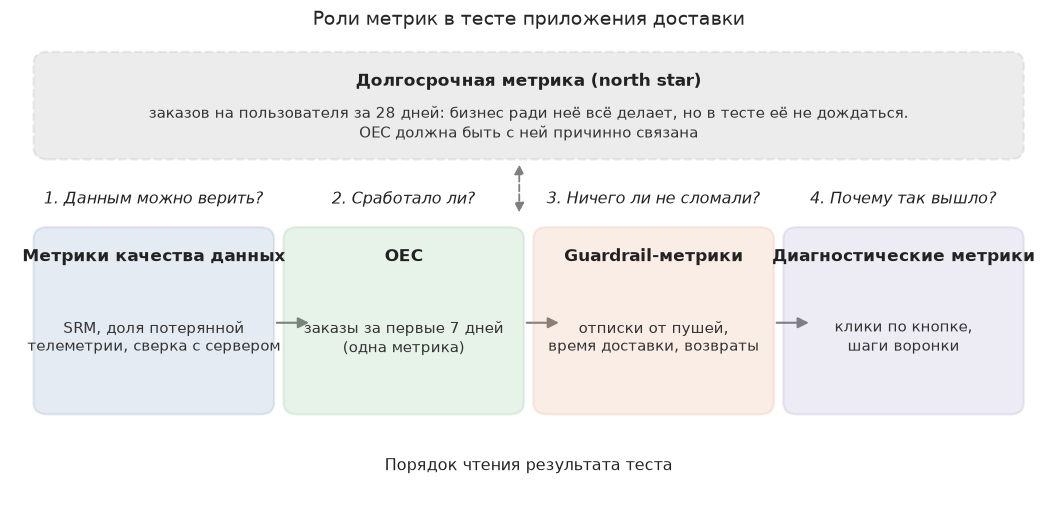

In [12]:
def draw_roles():
    fig, ax = plt.subplots(figsize=(11, 5.4))
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 6)
    ax.axis('off')
    ax.grid(False)

    def box(x, y, w, h, title, body, color, dashed=False):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.15', facecolor=color, edgecolor=GRAY if dashed else color,
                                    alpha=.14, linewidth=1.6, linestyle='--' if dashed else '-'))
        ax.text(x + w / 2, y + h - .32, title, ha='center', va='center', fontsize=12.5, fontweight='bold', color='#222222')
        ax.text(x + w / 2, y + h / 2 - .22, body, ha='center', va='center', fontsize=10.5, color='#333333', linespacing=1.35)

    box(.3, 4.5, 10.4, 1.25, 'Долгосрочная метрика (north star)', 'заказов на пользователя за 28 дней: бизнес ради неё всё делает, но в тесте её не дождаться.\nOEC должна быть с ней причинно связана', GRAY, dashed=True)
    steps = [
        (.3, 'Данным можно верить?', 'Метрики качества данных', 'SRM, доля потерянной\nтелеметрии, сверка с сервером', BLUE),
        (2.95, 'Сработало ли?', 'OEC', 'заказы за первые 7 дней\n(одна метрика)', GREEN),
        (5.6, 'Ничего ли не сломали?', 'Guardrail-метрики', 'отписки от пушей,\nвремя доставки, возвраты', ORANGE),
        (8.25, 'Почему так вышло?', 'Диагностические метрики', 'клики по кнопке,\nшаги воронки', PURPLE),
    ]
    for k, (x, question, title, body, color) in enumerate(steps):
        ax.text(x + 1.225, 3.95, f'{k + 1}. {question}', ha='center', va='center', fontsize=11.5, color='#222222', style='italic')
        box(x, 1.3, 2.45, 2.25, title, body, color)
        if k < 3:
            ax.add_patch(FancyArrowPatch((x + 2.5, 2.4), (x + 2.9, 2.4), arrowstyle='-|>', mutation_scale=16, color=GRAY, linewidth=1.5))
    ax.add_patch(FancyArrowPatch((5.4, 3.75), (5.4, 4.42), arrowstyle='<|-|>', mutation_scale=14, color=GRAY, linewidth=1.3, linestyle='--'))
    ax.text(5.5, .55, 'Порядок чтения результата теста', ha='center', fontsize=11.5, color='#222222')
    ax.set_title('Роли метрик в тесте приложения доставки', fontsize=14, pad=8)
    plt.tight_layout()
    plt.show()


draw_roles()

### Разные метрики тестируются по-разному

Поправка на множественность следует из правила запуска, а не навешивается на все метрики одинаково (фреймворк Spotify, [arXiv:2402.11609](https://arxiv.org/abs/2402.11609); сегменты и множественность при анализе — встреча 6).

* **Основная метрика (OEC / success)** — одна, поэтому тестируем без поправки.
* **Вторичные (диагностические)** — читаем как заранее определённое «семейство»: если их много, «хотя бы одна» почти наверняка выстрелит случайно, поэтому применяем поправку (например Холма) по семейству.
* **Guardrail** — односторонний non-inferiority без поправки на α: условие «все должны пройти» не накапливает α, но снижает мощность, поэтому поправляют β — каждый guardrail считают на мощность $1 - \frac{\beta}{G+1}$. Промахи складываются: $P(\text{промах}) \le \beta_{OEC} + \sum_g \beta_g$. Если и OEC посчитана на $1 - \beta/(G+1)$, общий промах ≤ β. Если OEC оставлена на $1 - \beta$, как в кейсе чекаута, общий промах ≤ $\beta + G\beta/(G+1)$.

| Роль | Что проверяем | Правило запуска | Уровень значимости | Мощность |
|---|---|---|---|---|
| Основная (OEC / success) | superiority | одна метрика | α, без поправки | 1 − β (или 1 − β/(G+1), если нужен общий промах ≤ β) |
| Вторичные (диагностические) | superiority | «хотя бы одна» как объяснение | α с поправкой по семейству | не планируем |
| Guardrail | non-inferiority | «все значимо не хуже» | односторонний, α без поправки | 1 − β/(G+1) |


## Часть 3. Как ускорить тест

Когда метрики выбраны, остаётся сократить длительность теста: главный рычаг здесь — дисперсия.

Метрики, α и MDE согласованы — остаётся дисперсия. Длительность теста напрямую зависит от размера выборки. Вспомним формулу из части 1 для одной группы при равных дисперсиях и двусторонней альтернативе ($s = 2$):

$$
N = \frac{\left( \Phi^{-1}_{(1 - \alpha/2)} + \Phi^{-1}_{(1-\beta)} \right)^2 \times 2 \sigma^2}{MDE^2}
$$

Осталась дисперсия $\sigma^2$, и $N$ линейно зависит от неё: снизив дисперсию вдвое, мы вдвое сократим тест.

**Попробуйте сами.** Эта ячейка интерактивная: запустите её в Colab или Jupyter и подвигайте ползунки.


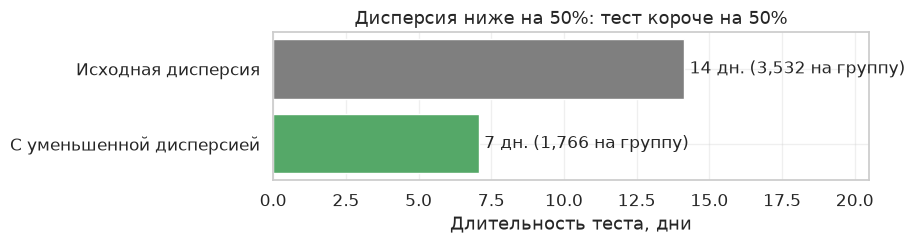

In [13]:
def duration_demo(mde: float = 20.0, sigma: float = 300.0, variance_cut: float = 0.5, daily_users: int = 500) -> None:
    """Показывает, как снижение дисперсии сокращает необходимую выборку и длительность теста."""
    z_sum = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
    sizes = [2 * z_sum ** 2 * sigma ** 2 * share / mde ** 2 for share in (1.0, 1 - variance_cut)]
    days = [2 * size / daily_users for size in sizes]

    fig, ax = plt.subplots(figsize=(9, 2.6))
    bars = ax.barh(['С уменьшенной дисперсией', 'Исходная дисперсия'], days[::-1], color=[GREEN, GRAY])
    ax.bar_label(bars, labels=[f'{d:.0f} дн. ({s:,.0f} на группу)' for d, s in zip(days[::-1], sizes[::-1])], padding=4)
    ax.set_xlim(0, days[0] * 1.45)
    ax.set_xlabel('Длительность теста, дни')
    ax.set_title(f'Дисперсия ниже на {variance_cut:.0%}: тест короче на {variance_cut:.0%}')
    plt.tight_layout()
    plt.show()


duration_demo()  # статичный вызов с параметрами по умолчанию

# Интерактивная версия: раскомментируйте строки ниже в Jupyter или Colab и двигайте ползунки
# interact(duration_demo,
#          mde=FloatSlider(value=20, min=5, max=100, step=5, description='MDE'),
#          sigma=FloatSlider(value=300, min=50, max=1000, step=50, description='σ'),
#          variance_cut=FloatSlider(value=0.5, min=0, max=0.9, step=0.05, description='Снижение σ²'),
#          daily_users=IntSlider(value=500, min=100, max=5000, step=100, description='Трафик/день'));


## Методы уменьшения дисперсии

| Метод | Что делает | Что для него нужно |
|---|---|---|
| Очистка от выбросов | Ограничивает влияние экстремальных значений | Порог или список пользователей, не зависящие от воздействия |
| Стратификация | Убирает дисперсию между сегментами | Сегменты, известные до теста |
| Бакетизация | **Не снижает дисперсию эффекта**, ускоряет вычисления | Случайное разбиение пользователей на бакеты |
| Линеаризация | **Не снижает дисперсию сама**, делает метрику отношения пользовательской | Числитель и знаменатель по пользователям |
| CUPED | Вычитает объяснимую ковариатой часть метрики | Ковариата, не зависящая от воздействия |

Что ещё бывает: VWE (веса по шумности пользователя), Predictive CUPED, CUPAC и MLRATE (ковариата из ML-модели). Здесь их не разбираем.


### [Стратификация](https://habr.com/ru/companies/X5Tech/articles/596279/)


Стратификация снижает дисперсию за счёт дополнительной информации о пользователях.

Для понимания стратификации введём несколько определений:

* **Популяция** – все пользователи (или объекты), на которых мы можем повлиять экспериментом. Например, 10 тысяч активных пользователей интернет-магазина.
* **Ковариата** – метрика, которая:
    * коррелирует с целевой метрикой;
    * может быть измерена до начала эксперимента;
    * не зависит от воздействия.

  Для экспериментов с людьми это пол, возраст, город, операционная система. Для магазинов — торговая площадь или режим работы.
* **Страты** – непересекающиеся подмножества популяции, каждое со своим набором значений ковариат.

Дисперсия метрики раскладывается на сумму дисперсии *внутри* страт и дисперсии *между* стратами (закон полной дисперсии):

$$
\sigma^2 = \sum_{k=1}^K w_k \sigma_k^2 + \sum_{k=1}^K w_k (\mu_k - \mu)^2
$$

Стратификация **убирает вторую часть**, поэтому общая дисперсия оценки снижается. Есть два подхода: стратифицированное сэмплирование и постстратификация. Посчитаем оба на примере двух равных страт со средними 2000 и 3000.


#### Стратифицированное сэмплирование

**Стратифицированное сэмплирование (пред-стратификация)** – способ формировать контрольную и экспериментальную группы так, чтобы доли страт в них были равны долям страт в популяции. Для этого определяем нужное число представителей каждой страты и случайно отбираем их из неё.

<br></br>

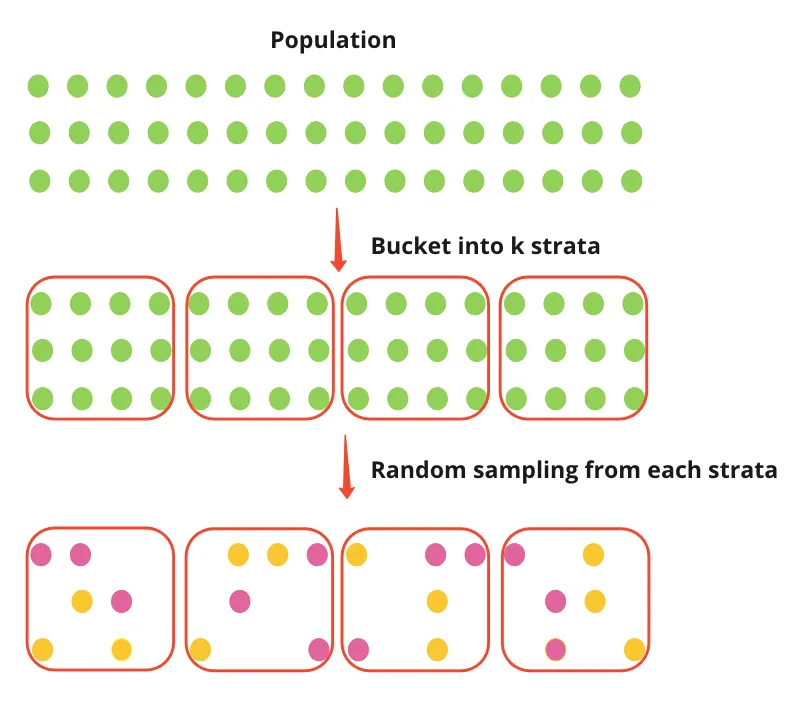


Дисперсия: 640,625 = 390,625 (внутри страт) + 250,000 (между стратами)
Расчётный объём выборки на группу: 1006



                                       Ошибка I рода  Мощность  SD оценки  Средняя SE
Случайно, обычное среднее                      0.048     0.791     35.674      35.674
Страт. сэмплирование, обычное среднее          0.012     0.854     27.518      35.685
Страт. сэмплирование, страт. среднее           0.054     0.952     28.241      27.878
Постстратификация                              0.052     0.946     28.013      27.862


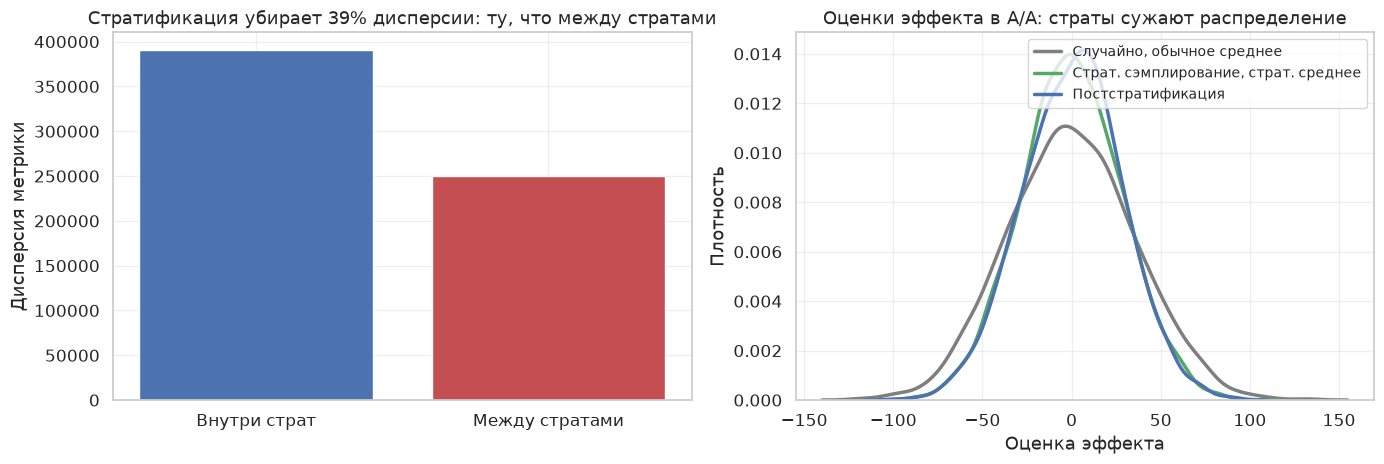

In [14]:
STRAT_CONFIG = {
    "alpha": ALPHA,
    "beta": 0.2,
    "effect": 100.0,
    "weights": (0.5, 0.5),  # доли страт в популяции
    "means": (2_000.0, 3_000.0),
    "stds": (625.0, 625.0),
}
strat_weights = np.array(STRAT_CONFIG["weights"])
strat_means = np.array(STRAT_CONFIG["means"])
strat_stds = np.array(STRAT_CONFIG["stds"])

# Общая дисперсия метрики: среднее дисперсий внутри страт + разброс средних между стратами
overall_mean = strat_weights @ strat_means
var_within = strat_weights @ strat_stds ** 2
var_between = strat_weights @ (strat_means - overall_mean) ** 2
var_total = var_within + var_between

z_sum = stats.norm.ppf(1 - STRAT_CONFIG["alpha"] / 2) + stats.norm.ppf(1 - STRAT_CONFIG["beta"])
strat_sample_size = int(np.ceil(2 * z_sum ** 2 * var_total / STRAT_CONFIG["effect"] ** 2))
print(f'Дисперсия: {var_total:,.0f} = {var_within:,.0f} (внутри страт) + {var_between:,.0f} (между стратами)')
print(f'Расчётный объём выборки на группу: {strat_sample_size}\n')


def generate_group(rng: np.random.Generator, size: tuple[int, int], stratified: bool, effect: float = 0.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует метрику и принадлежность к первой страте для группы с фиксированными или случайными долями страт."""
    if stratified:
        in_first = np.broadcast_to(np.arange(size[1]) < round(size[1] * strat_weights[0]), size)
    else:
        in_first = rng.random(size) < strat_weights[0]
    means = np.where(in_first, strat_means[0], strat_means[1])
    stds = np.where(in_first, strat_stds[0], strat_stds[1])
    return rng.normal(means + effect, stds), in_first


def plain_estimate(y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает обычное среднее и выборочную дисперсию метрики."""
    return y.mean(axis=1), y.var(axis=1, ddof=1)


def strat_estimate(y: np.ndarray, in_first: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает стратифицированное среднее и взвешенную дисперсию внутри страт."""
    mean_one, var_one, _ = masked_mean_var(y, in_first)
    mean_two, var_two, _ = masked_mean_var(y, ~in_first)
    return (strat_weights[0] * mean_one + strat_weights[1] * mean_two,
            strat_weights[0] * var_one + strat_weights[1] * var_two)


def simulate_strat(n: int, n_simulations: int = 4_000, batch: int = 500) -> dict[str, dict[str, np.ndarray]]:
    """Сравнивает способы формирования групп и оценки среднего на A/A и A/B."""
    rng = np.random.default_rng(42)
    # Название: (стратифицированное сэмплирование, стратифицированное среднее)
    schemes = {
        'Случайно, обычное среднее': (False, False),
        'Страт. сэмплирование, обычное среднее': (True, False),
        'Страт. сэмплирование, страт. среднее': (True, True),
        'Постстратификация': (False, True),
    }
    result = {name: {'aa': [], 'ab': [], 'delta': [], 'se': []} for name in schemes}
    for _ in range(n_simulations // batch):
        for key, effect in (('aa', 0.0), ('ab', STRAT_CONFIG['effect'])):
            for name, (stratified, use_strat_mean) in schemes.items():
                y_c, first_c = generate_group(rng, (batch, n), stratified)
                y_t, first_t = generate_group(rng, (batch, n), stratified, effect)
                mean_c, var_c = strat_estimate(y_c, first_c) if use_strat_mean else plain_estimate(y_c)
                mean_t, var_t = strat_estimate(y_t, first_t) if use_strat_mean else plain_estimate(y_t)
                delta, se = mean_t - mean_c, np.sqrt((var_c + var_t) / n)
                result[name][key].append(z_pvalue(delta, se) < ALPHA)
                if key == 'aa':
                    result[name]['delta'].append(delta)
                    result[name]['se'].append(se)
    return {name: {key: np.concatenate(values) for key, values in row.items()} for name, row in result.items()}


strat_results = simulate_strat(strat_sample_size)
print(pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'SD оценки': row['delta'].std(),
        'Средняя SE': row['se'].mean(),
    } for name, row in strat_results.items()
}).T.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(['Внутри страт', 'Между стратами'], [var_within, var_between], color=[BLUE, RED])
axes[0].set_title(f'Стратификация убирает {var_between / var_total:.0%} дисперсии: ту, что между стратами')
axes[0].set_ylabel('Дисперсия метрики')
styles = {'Случайно, обычное среднее': GRAY, 'Страт. сэмплирование, страт. среднее': GREEN, 'Постстратификация': BLUE}
for name, color in styles.items():
    sns.kdeplot(strat_results[name]['delta'], ax=axes[1], label=name, color=color, linewidth=2.5)
axes[1].set_title('Оценки эффекта в A/A: страты сужают распределение')
axes[1].set_xlabel('Оценка эффекта')
axes[1].set_ylabel('Плотность')
axes[1].legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()


Стратифицированное сэмплирование сильно уменьшило вероятности ошибок I и II рода, но это не совсем тот тест, который мы хотели. Мы планировали уровень значимости 0.05, а фактическая ошибка I рода ≈ 0.012. Распределение оценок эффекта стало уже: его реальное стандартное отклонение равно 27.5. Но t-тест не знает, что группы собраны не случайно, и считает завышенную стандартную ошибку (35.7). Вернуть тест на нужный уровень значимости поможет стратифицированное среднее.


#### Стратифицированное среднее

Оно вычисляется как взвешенная сумма средних каждой страты, где веса – доли страт в популяции.

Пусть $Y$ — целевая метрика, $k$ — индекс страты, $w_k$ — доля страты $k$ в популяции, $\bar{Y}_k$ — выборочное среднее метрики в страте $k$. Тогда стратифицированное среднее равно

$$
\bar{Y}_{strat} = \sum_{k=1}^K w_k \bar{Y}_k
$$

Обратим внимание на два свойства.

* При стратифицированном сэмплировании ($n_k = w_k n$) стратифицированное среднее совпадает с выборочным:

$$
\bar{Y}_{strat} = \sum_{k=1}^K w_k \bar{Y}_k = \sum_{k=1}^K w_k \frac{1}{n_k} \sum_{j=1}^{n_{k}} Y_{kj} = \sum_{k=1}^K \frac{n_k}{n} \frac{1}{n_k} \sum_{j=1}^{n_{k}} Y_{kj} = \frac{1}{n} \sum_{k=1}^K \sum_{j=1}^{n_{k}} Y_{kj} = \bar{Y}
$$

* Обычное и стратифицированное средние — несмещённые оценки одной и той же величины $\mu$. Для стратифицированного среднего при случайном сэмплировании это верно, если в каждую страту попало хотя бы одно наблюдение:

$$
\mathbb{E}(\bar{Y}) = \frac{1}{n} \sum_{k=1}^K \sum_{j=1}^{n_{k}} \mathbb{E} (Y_{kj}) = \mu, \qquad
\mathbb{E}(\bar{Y}_{strat}) = \sum_{k=1}^K w_k \mathbb{E}(\bar{Y}_{k}) = \sum_{k=1}^K w_k \mu_{k} = \mu
$$

Различаются они **дисперсией**. Для стратифицированного среднего при $n_k = w_k n$

$$
\mathbb{V}(\bar{Y}_{strat}) = \frac{1}{n} \sum_{k=1}^K w_k \sigma_k^2
$$

Подставив оценки $\hat{\sigma}_k^2$, получим статистику теста. При большом $n$ она приблизительно нормальна:

$$
t = \frac{\bar{Y}_{strat, B} - \bar{Y}_{strat, A}}{\sqrt{\hat{\mathbb{V}}(\bar{Y}_{strat, A}) + \hat{\mathbb{V}}(\bar{Y}_{strat, B})}} \approx \mathcal{N}(0, 1)
$$

С такой статистикой ошибка I рода в таблице выше вернулась к 0.054, а мощность выросла с 0.791 до 0.952. Под стратификацией обычно и понимают сочетание стратифицированного сэмплирования и стратифицированного среднего.


#### Постстратификация

**Постстратификация** – подход, при котором группы формируются случайно, а для оценки среднего используется **стратифицированное среднее**. Он нужен, когда управлять составом групп нельзя, и на практике применяется чаще: достаточно знать страту каждого пользователя на момент анализа.

Запишем дисперсии среднего для трёх схем:

$$
\mathbb{V}_{rand}(\bar{Y}) = \frac{1}{n} \sum_k w_k \sigma_k^2 + \frac{1}{n} \sum_k w_k (\mu_k - \mu)^2, \qquad
\mathbb{V}_{strat}(\bar{Y}_{strat}) = \frac{1}{n} \sum_k w_k \sigma_k^2
$$

$$
\mathbb{V}_{post}(\bar{Y}_{strat}) \approx \mathbb{V}_{strat}(\bar{Y}_{strat}) + \frac{1}{n^2} \sum_k (1 - w_k) \sigma_k^2
$$

Плата за случайный состав групп имеет порядок $1/n^2$, а выигрыш — $1/n$. Поэтому на больших выборках постстратификация почти не уступает стратификации, как и в нашей таблице (0.052 и 0.946). Обычно

$$
\mathbb{V}_{strat}(\bar{Y}_{strat}) \le \mathbb{V}_{post}(\bar{Y}_{strat}) \le \mathbb{V}_{rand}(\bar{Y})
$$

но правое неравенство не гарантировано: при малых $n$, слабых различиях между стратами или большом их числе постстратификация может оказаться хуже обычного среднего. На практике также следите, чтобы страты были определены **до** теста, чтобы воздействие не могло перевести пользователя из страты в страту, а в каждой группе были представители всех страт.

<br></br>

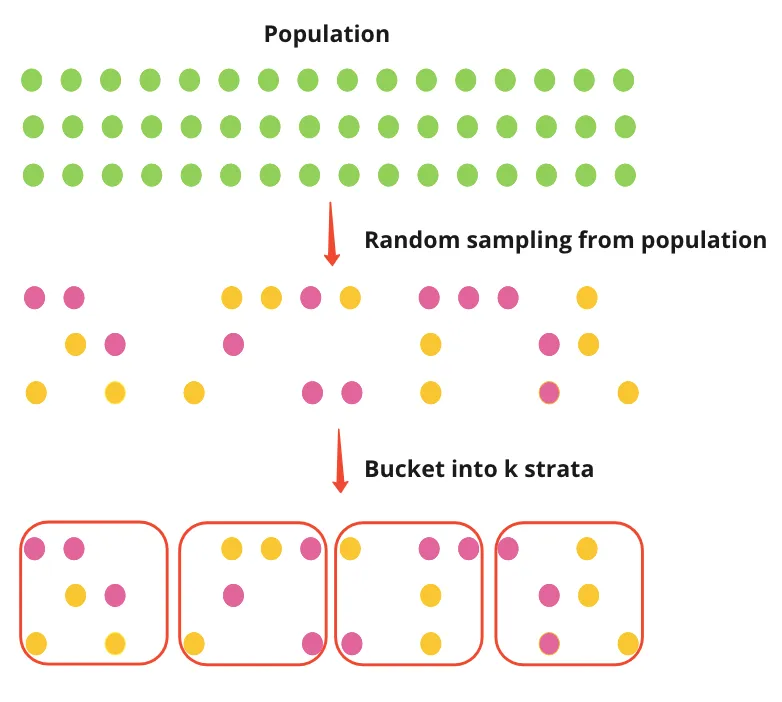

**Попробуйте сами.** Установите разнос страт 0, $n$ = 20 и увеличьте число страт: постстратификация станет хуже случайного разбиения.


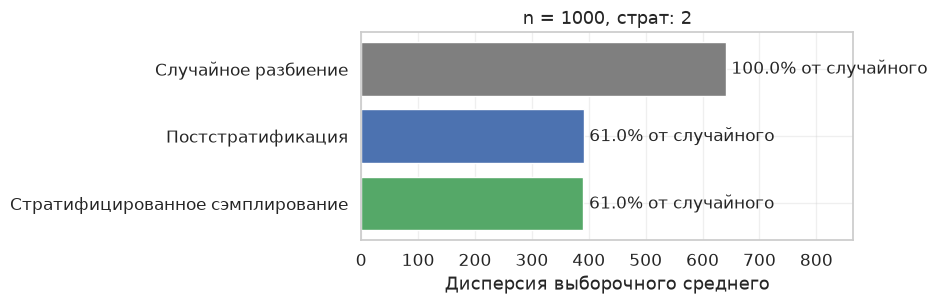

In [15]:
def strat_variance_demo(between_gap: float = 1000.0, n: int = 1000, strat_std: float = 625.0, n_strata: int = 2) -> None:
    """Сравнивает теоретические дисперсии среднего при случайном разбиении, стратификации и постстратификации."""
    weights = np.full(n_strata, 1 / n_strata)
    means = np.linspace(-between_gap / 2, between_gap / 2, n_strata)
    between = weights @ means ** 2
    v_strat = strat_std ** 2 / n
    v_rand = v_strat + between / n
    v_post = v_strat + (1 - weights).sum() * strat_std ** 2 / n ** 2

    fig, ax = plt.subplots(figsize=(9, 3.2))
    labels = ['Случайное разбиение', 'Постстратификация', 'Стратифицированное сэмплирование']
    values = np.array([v_rand, v_post, v_strat])[::-1]
    bars = ax.barh(labels[::-1], values, color=[GREEN, BLUE, GRAY])
    ax.bar_label(bars, labels=[f'{v / v_rand:.1%} от случайного' for v in values], padding=4)
    ax.set_xlim(0, values.max() * 1.35)
    ax.set_xlabel('Дисперсия выборочного среднего')
    ax.set_title(f'n = {n}, страт: {n_strata}')
    plt.tight_layout()
    plt.show()


strat_variance_demo()  # статичный вызов с параметрами по умолчанию

# Интерактивная версия: раскомментируйте строки ниже в Jupyter или Colab и двигайте ползунки
# interact(strat_variance_demo,
#          between_gap=FloatSlider(value=1000, min=0, max=3000, step=100, description='Разнос страт'),
#          n=IntSlider(value=1000, min=20, max=2000, step=20, description='n'),
#          strat_std=FloatSlider(value=625, min=100, max=1500, step=25, description='σ в страте'),
#          n_strata=IntSlider(value=2, min=2, max=20, step=1, description='Страт'));


### [CUPED](https://habr.com/ru/companies/X5Tech/articles/780270/)


**CUPED (Controlled-experiment Using Pre-Experiment Data)** ([Deng et al., 2013](https://doi.org/10.1145/2433396.2433413)) — высокоэффективный метод снижения дисперсии метрик. Его идея — вычесть из теста и контроля нечто такое, чтобы математическое ожидание разницы осталось прежним, а дисперсия уменьшилась.

Для этого нужна ковариата — метрика, скоррелированная с целевой и не зависящая от эксперимента. Чаще всего это значение той же метрики на периоде до эксперимента. Обозначим целевую метрику как $Y$, а ковариату как $X$.

Суть метода CUPED — в переходе от метрики $Y$ к метрике

$$
Y_{cuped} = Y - \theta (X - \bar{X}), \text{ где } \theta - \text{некоторое число, а } \bar{X} - \text{среднее ковариаты по обеим группам}
$$

Значения CUPED-метрики подаются в статистический критерий вместо исходных. Точечная оценка эффекта — разница средних CUPED-метрики в группах. При случайном распределении пользователей $\mathbb{E}(\bar{X}^{test}) = \mathbb{E}(\bar{X}^{ctrl})$, то есть в обеих группах в среднем вычитается одно и то же, и оценка эффекта не смещена. Оценка $\theta$ по тем же данным добавляет лишь пренебрежимо малое смещение.

Центрирование $X - \bar{X}$ на разницу средних не влияет, если $\theta$ в группах общий. Но оно сохраняет исходный уровень метрики, что нужно для относительного эффекта.

Посмотрим, как меняется дисперсия оценки среднего:

$$
\mathbb{V}(\overline{Y}_{cuped}) = \dfrac{\mathbb{V}\left(Y - \theta X\right)}{n} = \dfrac{\mathbb{V} (Y) - 2\theta\,\mathrm{cov}\left(Y,X\right) + \theta^2\mathbb{V} (X)}{n}
$$

Дисперсия квадратично зависит от $\theta$. Это парабола с точкой минимума

$$
\theta_0 = \frac{\mathrm{cov}(Y,X)}{\mathbb{V} (X)}
$$

Минимальная дисперсия равна

$$
\min\left(\mathbb{V} (\overline{Y}_{cuped})\right) = \mathbb{V} (\overline{Y}) \cdot \left(1 - \rho^2\right), \qquad \text{где } \rho = \frac{\mathrm{cov}(Y,X)} {\sqrt{\mathbb{V} (Y) \mathbb{V} (X)}}
$$

Значит, размер выборки сокращается в $1 / (1 - \rho^2)$ раз. Чем сильнее ковариата коррелирует с метрикой, тем больше выигрыш.

**Алгоритм применения CUPED**

1. Вычислить значения метрики $Y$ для каждого пользователя в обеих группах.
2. Вычислить значения ковариаты $X$ для каждого пользователя в обеих группах.
3. Вычислить $\theta = \frac{\mathrm{cov}(Y,X)}{\mathbb{V} (X)}$ по объединённым данным.
4. Для каждого пользователя вычислить $Y_{cuped} = Y - \theta (X - \bar{X})$.
5. Применить статистический тест к значениям CUPED-метрики.

**Новые пользователи.** Если у пользователя нет данных до эксперимента, ковариату заполняют одним и тем же правилом в обеих группах (например, средним или нулём). Оценка остаётся несмещённой, но для таких пользователей CUPED не даст выигрыша.


#### Симуляция


Дисперсия CUPED-метрики / исходной: 0.510
Теория 1 - ρ²:                      0.510


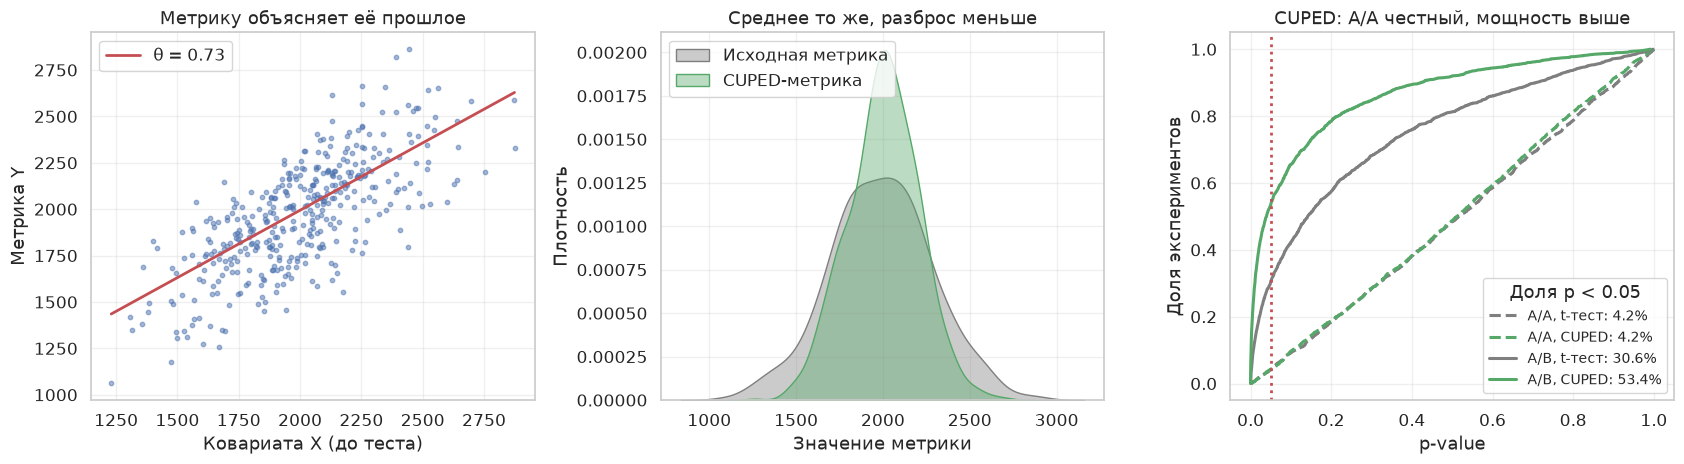

In [16]:
CUPED_CONFIG = {
    "n_simulations": 2_000,
    "sample_size": 1_000,
    "corr": 0.7,
    "effect": 20.0,
    "mean": 2_000.0,
    "sigma": 300.0,
}


def generate_metric_covariate(rng: np.random.Generator, size: tuple[int, int], corr: float, mean: float = 2_000.0,
                              sigma: float = 300.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует метрику и ковариату с заданной корреляцией."""
    covariate = rng.normal(0, 1, size)
    metric = corr * covariate + np.sqrt(1 - corr ** 2) * rng.normal(0, 1, size)
    return mean + sigma * metric, mean + sigma * covariate


def calculate_theta(metric: np.ndarray, covariate: np.ndarray) -> np.ndarray:
    """Считает коэффициент θ для CUPED по строкам."""
    cov_centered = covariate - covariate.mean(axis=1, keepdims=True)
    metric_centered = metric - metric.mean(axis=1, keepdims=True)
    return (cov_centered * metric_centered).sum(axis=1, keepdims=True) / (cov_centered ** 2).sum(axis=1, keepdims=True)


def apply_cuped(y_c: np.ndarray, x_c: np.ndarray, y_t: np.ndarray, x_t: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Считает CUPED-метрику обеих групп с общим θ и общим средним ковариаты."""
    pooled_x = np.hstack([x_c, x_t])
    theta = calculate_theta(np.hstack([y_c, y_t]), pooled_x)
    x_mean = pooled_x.mean(axis=1, keepdims=True)
    return y_c - theta * (x_c - x_mean), y_t - theta * (x_t - x_mean)


def plot_pvalue_ecdf(ax: plt.Axes, pvalues: dict[str, tuple[np.ndarray, str]]) -> None:
    """Рисует эмпирические функции распределения p-value: высота при α равна доле отклонений H0."""
    for name, (values, color) in pvalues.items():
        sorted_p = np.sort(values)
        style = '--' if 'A/A' in name else '-'
        ax.plot(sorted_p, np.arange(1, sorted_p.size + 1) / sorted_p.size, color=color, linestyle=style, linewidth=2.2,
                label=f'{name}: {np.mean(values < ALPHA):.1%}')
    ax.axvline(ALPHA, color=RED, linestyle=':', linewidth=2)
    ax.set_xlabel('p-value')
    ax.set_ylabel('Доля экспериментов')


rng = np.random.default_rng(42)
size = (CUPED_CONFIG['n_simulations'], CUPED_CONFIG['sample_size'])
params = (CUPED_CONFIG['corr'], CUPED_CONFIG['mean'], CUPED_CONFIG['sigma'])
y_c, x_c = generate_metric_covariate(rng, size, *params)
y_t, x_t = generate_metric_covariate(rng, size, *params)
y_e = y_t + CUPED_CONFIG['effect']

cuped_c, cuped_aa = apply_cuped(y_c, x_c, y_t, x_t)
cuped_c_ab, cuped_ab = apply_cuped(y_c, x_c, y_e, x_t)
cuped_pvalues = {
    'A/A, t-тест': (stats.ttest_ind(y_t, y_c, axis=1).pvalue, GRAY),
    'A/A, CUPED': (stats.ttest_ind(cuped_aa, cuped_c, axis=1).pvalue, GREEN),
    'A/B, t-тест': (stats.ttest_ind(y_e, y_c, axis=1).pvalue, GRAY),
    'A/B, CUPED': (stats.ttest_ind(cuped_ab, cuped_c_ab, axis=1).pvalue, GREEN),
}
print(f"Дисперсия CUPED-метрики / исходной: {cuped_c.var(axis=1).mean() / y_c.var(axis=1).mean():.3f}")
print(f"Теория 1 - ρ²:                      {1 - CUPED_CONFIG['corr'] ** 2:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(x_c[0, :400], y_c[0, :400], s=10, alpha=0.5, color=BLUE)
theta_line = calculate_theta(y_c[:1], x_c[:1])[0, 0]
grid = np.array([x_c[0, :400].min(), x_c[0, :400].max()])
axes[0].plot(grid, y_c[0].mean() + theta_line * (grid - x_c[0].mean()), color=RED, linewidth=2, label=f'θ = {theta_line:.2f}')
axes[0].set_title('Метрику объясняет её прошлое')
axes[0].set_xlabel('Ковариата X (до теста)')
axes[0].set_ylabel('Метрика Y')
axes[0].legend()
sns.kdeplot(y_c[0], ax=axes[1], color=GRAY, fill=True, alpha=0.4, label='Исходная метрика')
sns.kdeplot(cuped_c[0], ax=axes[1], color=GREEN, fill=True, alpha=0.4, label='CUPED-метрика')
axes[1].set_title('Среднее то же, разброс меньше')
axes[1].set_xlabel('Значение метрики')
axes[1].set_ylabel('Плотность')
axes[1].legend()
plot_pvalue_ecdf(axes[2], cuped_pvalues)
axes[2].set_title('CUPED: A/A честный, мощность выше')
axes[2].legend(fontsize=10, title='Доля p < 0.05', loc='lower right')
plt.tight_layout()
plt.show()


Дисперсия упала до теоретических $1 - \rho^2$. На правом графике штриховые линии (A/A) идут вдоль диагонали, а значит, ошибка I рода корректна. Сплошная зелёная линия выше серой: при том же размере выборки CUPED обнаруживает эффект чаще.

**Попробуйте сами.** Двигайте $\theta$ и найдите значения, при которых CUPED **увеличивает** дисперсию.


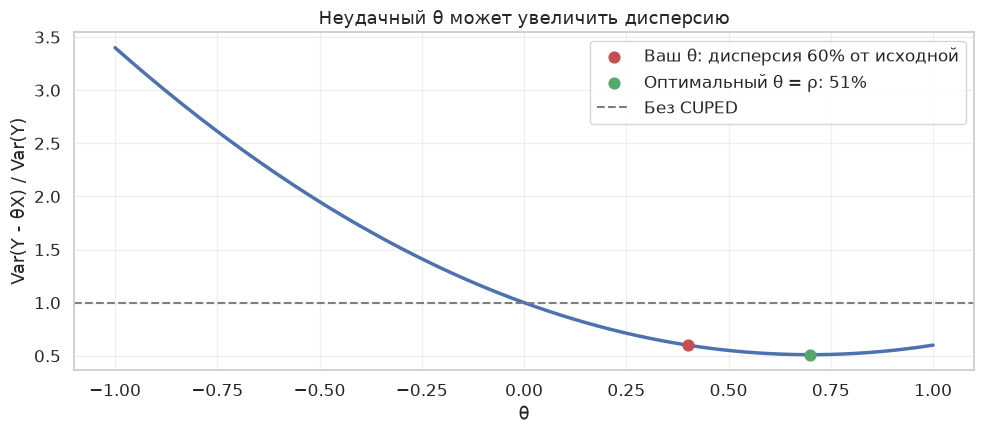

In [17]:
def cuped_demo(rho: float = 0.7, theta: float = 0.4) -> None:
    """Показывает зависимость дисперсии CUPED-метрики от θ при Var(X) = Var(Y) = 1."""
    thetas = np.linspace(-1, 1, 201)
    current = 1 - 2 * theta * rho + theta ** 2

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(thetas, 1 - 2 * thetas * rho + thetas ** 2, color=BLUE, linewidth=2.5)
    ax.scatter([theta], [current], color=RED, zorder=3, s=60, label=f'Ваш θ: дисперсия {current:.0%} от исходной')
    ax.scatter([rho], [1 - rho ** 2], color=GREEN, zorder=3, s=60, label=f'Оптимальный θ = ρ: {1 - rho ** 2:.0%}')
    ax.axhline(1, color=GRAY, linestyle='--', label='Без CUPED')
    ax.set_xlabel('θ')
    ax.set_ylabel('Var(Y - θX) / Var(Y)')
    ax.set_title('Неудачный θ может увеличить дисперсию')
    ax.legend()
    plt.tight_layout()
    plt.show()


cuped_demo()  # статичный вызов с параметрами по умолчанию

# Интерактивная версия: раскомментируйте строки ниже в Jupyter или Colab и двигайте ползунки
# interact(cuped_demo,
#          rho=FloatSlider(value=0.7, min=-0.95, max=0.95, step=0.05, description='ρ'),
#          theta=FloatSlider(value=0.4, min=-1, max=1, step=0.05, description='θ'));


Как зависит выигрыш от корреляции:


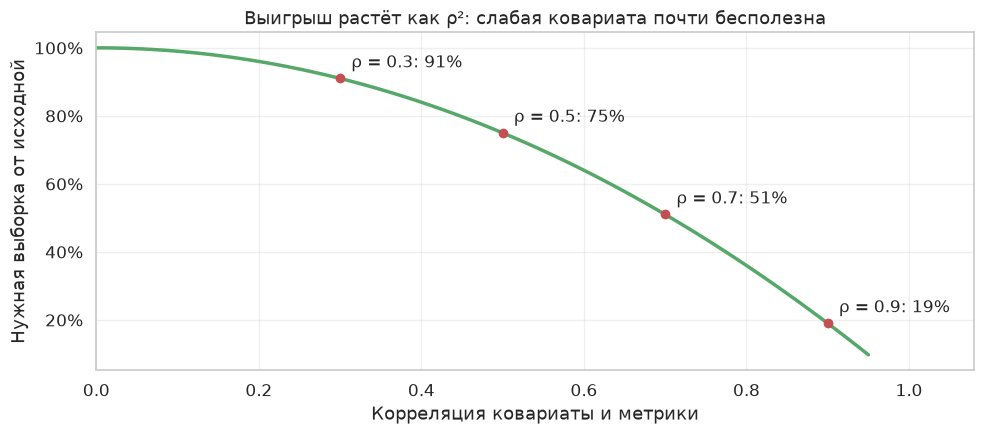

In [18]:
rhos = np.linspace(0, 0.95, 100)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rhos, 1 - rhos ** 2, color=GREEN, linewidth=2.5)
for rho in (0.3, 0.5, 0.7, 0.9):
    ax.scatter([rho], [1 - rho ** 2], color=RED, zorder=3)
    ax.annotate(f'ρ = {rho}: {1 - rho ** 2:.0%}', (rho, 1 - rho ** 2), textcoords='offset points', xytext=(8, 8))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlim(0, 1.08)
ax.set_xlabel('Корреляция ковариаты и метрики')
ax.set_ylabel('Нужная выборка от исходной')
ax.set_title('Выигрыш растёт как ρ²: слабая ковариата почти бесполезна')
plt.tight_layout()
plt.show()


**CUPED и регрессия.** Эффект CUPED с общим $\theta$ практически совпадает с коэффициентом при индикаторе группы в регрессии $Y = \alpha + \tau T + \theta X + \varepsilon$ (ANCOVA). Это помогает понимать и обобщать метод: несколько ковариат — это просто регрессия с несколькими признаками.

Ниже — один прогон и среднее по 2 000 прогонам при двух корреляциях. В одном прогоне оценка может заметно отличаться от истинных 20: это шум выборки (SE ≈ 9.5 при ρ = 0.7), а не смещение. Несмещённость видна только по многим прогонам.


In [19]:
rng = np.random.default_rng(42)
y_c_one, x_c_one = generate_metric_covariate(rng, (1, 1_000), 0.7)
y_t_one, x_t_one = generate_metric_covariate(rng, (1, 1_000), 0.7)
y_t_one = y_t_one + 20

cuped_c_one, cuped_t_one = apply_cuped(y_c_one, x_c_one, y_t_one, x_t_one)
design = np.column_stack([
    np.ones(2_000),
    np.r_[np.zeros(1_000), np.ones(1_000)],
    np.r_[x_c_one[0], x_t_one[0]],
])
ols = sm.OLS(np.r_[y_c_one[0], y_t_one[0]], design).fit()

print('Один прогон, ρ = 0.7, истинный эффект 20:')
print(f'  эффект по CUPED:               {cuped_t_one.mean() - cuped_c_one.mean():.3f}')
print(f'  коэффициент при T в регрессии: {ols.params[1]:.3f} (SE {ols.bse[1]:.1f})')

print('\n2 000 прогонов:')
for rho in (0.3, 0.7):
    rng = np.random.default_rng(7)
    y_c_r, x_c_r = generate_metric_covariate(rng, size, rho)
    y_t_r, x_t_r = generate_metric_covariate(rng, size, rho)
    c_r, t_r = apply_cuped(y_c_r, x_c_r, y_t_r + 20, x_t_r)
    estimates = t_r.mean(axis=1) - c_r.mean(axis=1)
    naive = (y_t_r + 20).mean(axis=1) - y_c_r.mean(axis=1)
    print(f'  ρ = {rho}: средняя оценка CUPED {estimates.mean():.2f} ± {2 * estimates.std() / np.sqrt(estimates.size):.2f}, '
          f'без CUPED {naive.mean():.2f}; Var CUPED / Var исходной = {c_r.var(axis=1).mean() / y_c_r.var(axis=1).mean():.3f} '
          f'(1 − ρ² = {1 - rho ** 2:.3f})')


Один прогон, ρ = 0.7, истинный эффект 20:
  эффект по CUPED:               36.876
  коэффициент при T в регрессии: 36.912 (SE 9.5)

2 000 прогонов:


  ρ = 0.3: средняя оценка CUPED 19.80 ± 0.57, без CUPED 19.80; Var CUPED / Var исходной = 0.910 (1 − ρ² = 0.910)


  ρ = 0.7: средняя оценка CUPED 19.85 ± 0.42, без CUPED 19.85; Var CUPED / Var исходной = 0.510 (1 − ρ² = 0.510)


### [Линеаризация](https://www.researchgate.net/publication/322969314_Consistent_Transformation_of_Ratio_Metrics_for_Efficient_Online_Controlled_Experiments)


Метрика отношения (CTR, средний чек, клики на сессию) считается как отношение сумм, поэтому её наблюдения — это показы или заказы, а не пользователи. Один пользователь даёт много зависимых наблюдений: единица анализа (показ) не совпадает с единицей рандомизации (пользователь), и обычный t-тест применять нельзя. Дисперсию можно посчитать дельта-методом. CUPED с ним тоже совместим — для ratio-метрик через дельта-метод он описан в той же статье [Deng et al., 2013](https://doi.org/10.1145/2433396.2433413), — но формулы громоздкие.

**Линеаризация** ([Budylin et al., 2018](https://doi.org/10.1145/3159652.3159699)) делает это проще: превращает метрику отношения в **пользовательскую метрику**, и дальше работает любой метод для пользовательских метрик — t-тест, CUPED, стратификация.

**Важно:** сама по себе линеаризация **не снижает дисперсию** и не делает тест мощнее дельта-метода, их p-value практически совпадают. Её ценность в том, что поверх новой метрики можно применить t-тест, CUPED и другие методы снижения дисперсии.

Для метрики отношения $\mathcal{R} = \frac{\sum_{u \in U} Y(u)}{\sum_{u \in U} X(u)}$ линеаризованная метрика равна

$$
Lin(u) = Y(u) - \mathcal{R}^{ctrl} X(u), \text{ где } \mathcal{R}^{ctrl} - \text{значение метрики отношения в контрольной группе}
$$

Посчитав $Lin(u)$ для каждого пользователя в обеих группах, сравниваем средние обычным t-тестом. Средняя метрика в контроле равна нулю, а разница средних связана с эффектом так:

$$
\overline{Lin}^{\,test} - \overline{Lin}^{\,ctrl} = \bar{X}^{test} \left( \mathcal{R}^{test} - \mathcal{R}^{ctrl} \right)
$$

Отсюда следуют две практические детали: знак эффекта всегда совпадает со знаком изменения исходной метрики, а чтобы получить эффект в единицах метрики отношения, разницу нужно поделить на $\bar{X}^{test}$. По той же причине MDE для линеаризованной метрики равен MDE метрики отношения, умноженному на средний знаменатель.

**Линеаризация с весами.** Пользователи с большим знаменателем могут вносить в метрику много шума. Чтобы снизить их влияние, наблюдения можно перевзвесить, например, на корень из знаменателя:

$$
\mathcal{R}_{rew} = \frac{\sum_u \sqrt{X(u)} \times \frac{Y(u)}{X(u)}}{\sum_u \sqrt{X(u)}}, \qquad
Lin_{rew}(u) = \sqrt{X(u)} \left( \frac{Y(u)}{X(u)} - \mathcal{R}_{rew}^{ctrl} \right)
$$

Это уже другая метрика с другими весами пользователей: такой вариант подходит для проверки гипотезы, но его эффект не равен эффекту на исходную метрику отношения.

Проверим всё это на CTR: у пользователей разная активность и разная склонность кликать, а воздействие поднимает CTR на 5%.


                              Ошибка I рода  Мощность
По показам, клики независимы          0.191     0.586
Среднее CTR пользователей             0.048     0.260
Дельта-метод                          0.052     0.340
Линеаризация                          0.052     0.346
Линеаризация с весами                 0.046     0.384
Линеаризация + CUPED                  0.048     0.462


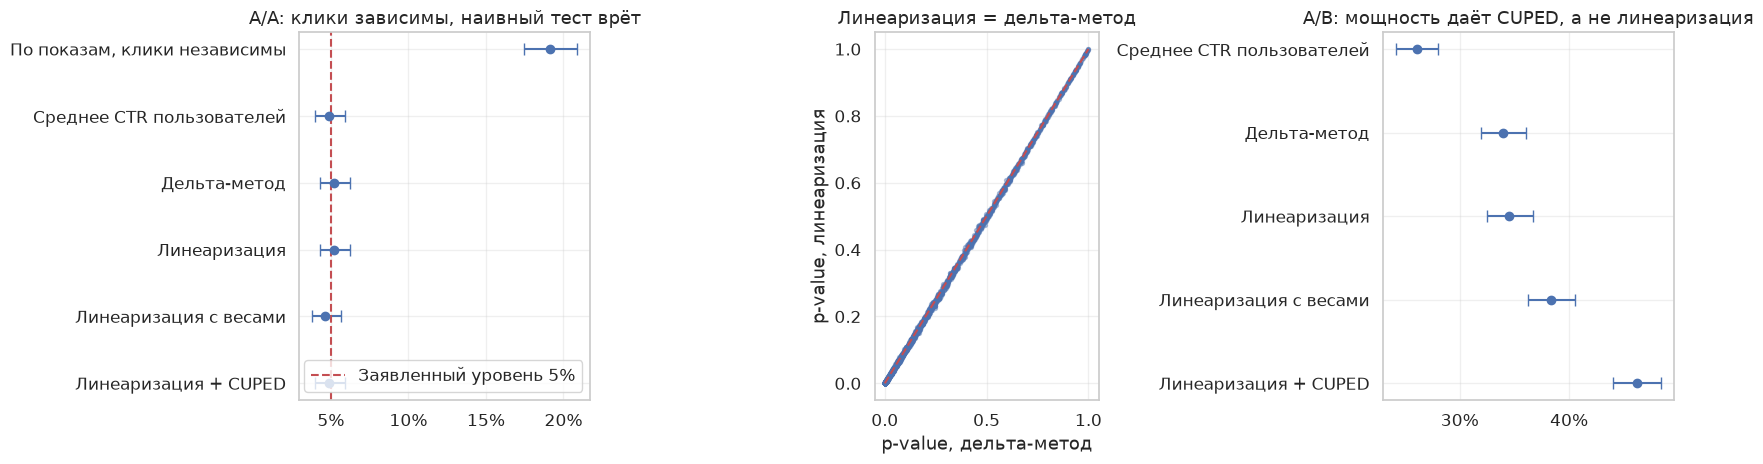

In [20]:
LIN_CONFIG = {
    "n_simulations": 2_000,
    "n_users": 3_000,
    "uplift": 0.05,  # рост CTR на 5%
}


def generate_ctr_data(rng: np.random.Generator, size: tuple[int, int], uplift: float = 0.0) -> dict[str, np.ndarray]:
    """Генерирует просмотры и клики пользователей до и во время эксперимента."""
    activity = rng.gamma(1.0, 12.0, size)  # у пользователей разная активность
    ctr = rng.beta(2, 18, size) * np.clip(1.6 - 0.03 * activity, 0.4, 1.6)  # и разная склонность кликать
    views_pre = 1 + rng.poisson(activity)
    views = 1 + rng.poisson(activity)
    return {
        'views_pre': views_pre,
        'clicks_pre': rng.binomial(views_pre, ctr),
        'views': views,
        'clicks': rng.binomial(views, np.minimum(ctr * (1 + uplift), 1)),
    }


def ratio_delta_var(views: np.ndarray, clicks: np.ndarray) -> np.ndarray:
    """Считает дисперсию ratio-метрики дельта-методом по пользовательским суммам."""
    n = views.shape[1]
    mean_x, mean_y = views.mean(axis=1, keepdims=True), clicks.mean(axis=1, keepdims=True)
    ratio = mean_y / mean_x
    return ((clicks - ratio * views) ** 2).sum(axis=1) / (n - 1) / (n * mean_x[:, 0] ** 2)


def ratio_tests(control: dict[str, np.ndarray], pilot: dict[str, np.ndarray]) -> dict[str, np.ndarray]:
    """Возвращает p-value разных критериев для метрики отношения."""
    x_c, y_c, x_t, y_t = control['views'], control['clicks'], pilot['views'], pilot['clicks']
    r_c = y_c.sum(axis=1, keepdims=True) / x_c.sum(axis=1, keepdims=True)
    r_t = y_t.sum(axis=1, keepdims=True) / x_t.sum(axis=1, keepdims=True)
    delta = (r_t - r_c)[:, 0]

    # Клики как независимые испытания: типичная ошибка
    se_naive = np.sqrt(r_c[:, 0] * (1 - r_c[:, 0]) / x_c.sum(axis=1) + r_t[:, 0] * (1 - r_t[:, 0]) / x_t.sum(axis=1))
    se_delta = np.sqrt(ratio_delta_var(x_c, y_c) + ratio_delta_var(x_t, y_t))

    lin_c, lin_t = y_c - r_c * x_c, y_t - r_c * x_t

    w_c, w_t = np.sqrt(x_c), np.sqrt(x_t)
    r_rew = ((w_c * y_c / x_c).sum(axis=1) / w_c.sum(axis=1))[:, None]
    rew_c, rew_t = (y_c - r_rew * x_c) / w_c, (y_t - r_rew * x_t) / w_t

    # CUPED поверх линеаризации: ковариата — та же линеаризованная метрика на предпериоде
    r_pre = control['clicks_pre'].sum(axis=1, keepdims=True) / control['views_pre'].sum(axis=1, keepdims=True)
    cov_c = control['clicks_pre'] - r_pre * control['views_pre']
    cov_t = pilot['clicks_pre'] - r_pre * pilot['views_pre']
    pooled_lin, pooled_cov = np.hstack([lin_c, lin_t]), np.hstack([cov_c, cov_t])
    centered_cov = pooled_cov - pooled_cov.mean(axis=1, keepdims=True)
    theta = ((pooled_lin * centered_cov).sum(axis=1) / (centered_cov ** 2).sum(axis=1))[:, None]

    return {
        'По показам, клики независимы': z_pvalue(delta, se_naive),
        'Среднее CTR пользователей': stats.ttest_ind(y_t / x_t, y_c / x_c, axis=1).pvalue,
        'Дельта-метод': z_pvalue(delta, se_delta),
        'Линеаризация': stats.ttest_ind(lin_t, lin_c, axis=1).pvalue,
        'Линеаризация с весами': stats.ttest_ind(rew_t, rew_c, axis=1).pvalue,
        'Линеаризация + CUPED': stats.ttest_ind(lin_t - theta * cov_t, lin_c - theta * cov_c, axis=1).pvalue,
    }


def simulate_ratio(n_simulations: int, n_users: int, uplift: float, batch: int = 200) -> dict[str, dict[str, np.ndarray]]:
    """Прогоняет A/A и A/B и собирает p-value всех критериев."""
    rng = np.random.default_rng(42)
    result: dict[str, dict[str, list]] = {'aa': {}, 'ab': {}}
    for _ in range(n_simulations // batch):
        for key, effect in (('aa', 0.0), ('ab', uplift)):
            control = generate_ctr_data(rng, (batch, n_users))
            pilot = generate_ctr_data(rng, (batch, n_users), effect)
            for name, pvalues in ratio_tests(control, pilot).items():
                result[key].setdefault(name, []).append(pvalues)
    return {key: {name: np.concatenate(values) for name, values in row.items()} for key, row in result.items()}


ratio_pvalues = simulate_ratio(**LIN_CONFIG)
print(pd.DataFrame({
    'Ошибка I рода': {name: np.mean(p < ALPHA) for name, p in ratio_pvalues['aa'].items()},
    'Мощность': {name: np.mean(p < ALPHA) for name, p in ratio_pvalues['ab'].items()},
}).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.3, 1, 1.3]})
plot_rates(axes[0], {name: p < ALPHA for name, p in ratio_pvalues['aa'].items()}, 'A/A: клики зависимы, наивный тест врёт')
axes[1].scatter(ratio_pvalues['ab']['Дельта-метод'], ratio_pvalues['ab']['Линеаризация'], s=8, alpha=0.4, color=BLUE)
axes[1].plot([0, 1], [0, 1], color=RED, linestyle='--')
axes[1].set_title('Линеаризация = дельта-метод')
axes[1].set_xlabel('p-value, дельта-метод')
axes[1].set_ylabel('p-value, линеаризация')
correct = [name for name in ratio_pvalues['ab'] if name != 'По показам, клики независимы']
plot_rates(axes[2], {name: ratio_pvalues['ab'][name] < ALPHA for name in correct}, 'A/B: мощность даёт CUPED, а не линеаризация', None)
plt.tight_layout()
plt.show()


Что видно по результатам:

* Если считать показы независимыми, ошибка I рода равна 19.1%. Это главная проблема, которую решают дельта-метод и линеаризация.
* Линеаризация и дельта-метод совпадают: точки на среднем графике лежат на диагонали, мощность 0.346 и 0.340.
* Среднее CTR пользователей — корректный тест, но **другой метрики**: каждый пользователь в нём весит одинаково, а не пропорционально показам. Поэтому и мощность другая (0.260), а значение метрики может заметно отличаться от общего CTR.
* Линеаризация с весами на этих данных мощнее (0.384), но это свойство данных, а не гарантия.
* Настоящий выигрыш даёт CUPED поверх линеаризации: мощность 0.462.

Проверим формулу перехода к единицам метрики отношения:


In [21]:
rng = np.random.default_rng(7)
control = generate_ctr_data(rng, (1, 200_000))
pilot = generate_ctr_data(rng, (1, 200_000), LIN_CONFIG['uplift'])

ratio_c = control['clicks'].sum() / control['views'].sum()
ratio_t = pilot['clicks'].sum() / pilot['views'].sum()
lin_c = control['clicks'] - ratio_c * control['views']
lin_t = pilot['clicks'] - ratio_c * pilot['views']

print(f"Эффект на CTR:                     {ratio_t - ratio_c:.5f}")
print(f"Эффект на линеаризованной метрике: {lin_t.mean() - lin_c.mean():.5f}")
print(f"Он же, делённый на X̄ теста:        {(lin_t.mean() - lin_c.mean()) / pilot['views'].mean():.5f}")


Эффект на CTR:                     0.00466
Эффект на линеаризованной метрике: 0.06045
Он же, делённый на X̄ теста:        0.00466


### [Очистка данных от выбросов](https://habr.com/ru/companies/avito/articles/571094/#:~:text=%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D1%8B%20%D0%B1%D0%BE%D1%80%D1%8C%D0%B1%D1%8B%20%D1%81%20%D0%B2%D1%8B%D0%B1%D1%80%D0%BE%D1%81%D0%B0%D0%BC%D0%B8%20%D0%B2%20%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D1%85)


Чем больше выбросов, тем выше дисперсия и тем менее мощный у нас критерий. Поэтому аналитикам часто приходит в голову **убрать n% пользователей с самой большой (или самой маленькой) метрикой в тесте и контроле**.

Идея здравая, но подходить к ней нужно осторожно:

1. Неправильная реализация может исказить результаты эксперимента.
2. Убирая топ пользователей и принимая решение по остальным, мы неявно считаем, что топ-пользователи отреагируют на изменение так же, как остальные, или лучше. Это не всегда так, и это стоит проверять отдельно.

Сравним способы очистки на одних и тех же данных. Выручка пользователя скошена вправо, средняя выручка равна 1000. В A/B-тесте она вырастает у всех на 15%, так что истинный эффект равен 150. Отрезаем верхний 1%.


Истинный эффект на всю аудиторию: 150
                                   Ошибка I рода  Мощность  Оценка эффекта  SD оценки  Средняя SE
Без очистки                                0.048     0.603         149.818     68.609      68.049
Свой порог в каждой группе                 0.083     0.699         137.360     61.150      54.037
Свой порог + поправка SE                   0.050     0.621         137.360     61.150      60.943
Общий порог по тесту и контролю            0.054     0.536         110.578     54.179      53.817
Порог по контролю                          0.054     0.466          98.138     51.777      51.878
Порог предпериода к метрике теста          0.056     0.518         104.315     51.841      51.800
Исключение по выручке до теста             0.048     0.603         147.653     67.386      66.918
Винзоризация порогом предпериода           0.051     0.623         132.991     59.072      58.753


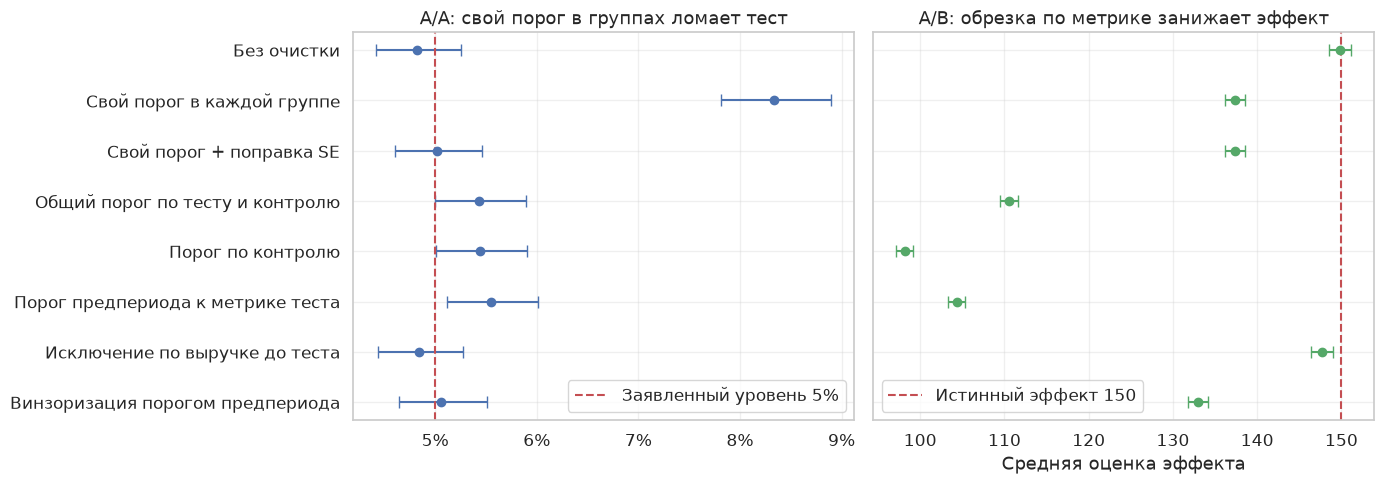

In [22]:
OUTLIER_CONFIG = {
    "n_simulations": 10_000,
    "sample_size": 1_000,
    "tail_share": 0.01,
    "lift": 1.15,  # эффект: выручка каждого пользователя выросла на 15%
}
OUTLIER_TRUE_EFFECT = 1_000 * (OUTLIER_CONFIG["lift"] - 1)


def generate_revenue(rng: np.random.Generator, size: tuple[int, int], lift: float = 1.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует выручку пользователя до и во время эксперимента. Средняя выручка до эксперимента равна 1000."""
    activity = rng.gamma(2, 500, size)  # постоянная часть: активные пользователи тратят больше в оба периода
    return activity * rng.exponential(1, size), lift * activity * rng.exponential(1, size)


def clean_and_compare(pre_c: np.ndarray, y_c: np.ndarray, pre_t: np.ndarray, y_t: np.ndarray,
                      tail_share: float) -> dict[str, tuple[np.ndarray, np.ndarray]]:
    """Применяет способы очистки и для каждого возвращает оценку эффекта и её стандартную ошибку."""
    level = 1 - tail_share
    n = y_c.shape[1]
    q_c = np.quantile(y_c, level, axis=1, keepdims=True)
    q_t = np.quantile(y_t, level, axis=1, keepdims=True)
    q_pooled = np.quantile(np.hstack([y_c, y_t]), level, axis=1, keepdims=True)
    q_pre = np.quantile(np.hstack([pre_c, pre_t]), level, axis=1, keepdims=True)

    def compare(x_c, mask_c, x_t, mask_t):
        mean_c, var_c, n_c = masked_mean_var(x_c, mask_c)
        mean_t, var_t, n_t = masked_mean_var(x_t, mask_t)
        return mean_t - mean_c, np.sqrt(var_c / n_c + var_t / n_t)

    everyone = np.ones_like(y_c, dtype=bool)
    per_group = compare(y_c, y_c <= q_c, y_t, y_t <= q_t)
    # SE усечённого среднего, учитывающая случайность порога: дисперсия винзоризованной метрики / (1 - доля)^2
    yuen_var = (np.minimum(y_c, q_c).var(axis=1, ddof=1) + np.minimum(y_t, q_t).var(axis=1, ddof=1)) / level ** 2
    return {
        'Без очистки': compare(y_c, everyone, y_t, everyone),
        'Свой порог в каждой группе': per_group,
        'Свой порог + поправка SE': (per_group[0], np.sqrt(yuen_var / n)),
        'Общий порог по тесту и контролю': compare(y_c, y_c <= q_pooled, y_t, y_t <= q_pooled),
        'Порог по контролю': compare(y_c, y_c <= q_c, y_t, y_t <= q_c),
        'Порог предпериода к метрике теста': compare(y_c, y_c <= q_pre, y_t, y_t <= q_pre),
        'Исключение по выручке до теста': compare(y_c, pre_c <= q_pre, y_t, pre_t <= q_pre),
        'Винзоризация порогом предпериода': compare(np.minimum(y_c, q_pre), everyone, np.minimum(y_t, q_pre), everyone),
    }


def simulate_outliers(n_simulations: int, sample_size: int, tail_share: float, lift: float,
                      batch: int = 500) -> dict[str, dict[str, np.ndarray]]:
    """Прогоняет A/A и A/B и собирает оценки эффекта, SE и решения по каждому способу очистки."""
    rng = np.random.default_rng(42)
    result: dict[str, dict[str, list]] = {}
    for _ in range(n_simulations // batch):
        for key, group_lift in (('aa', 1.0), ('ab', lift)):
            pre_c, y_c = generate_revenue(rng, (batch, sample_size))
            pre_t, y_t = generate_revenue(rng, (batch, sample_size), group_lift)
            for name, (delta, se) in clean_and_compare(pre_c, y_c, pre_t, y_t, tail_share).items():
                row = result.setdefault(name, {'aa': [], 'ab': [], 'delta': [], 'se': []})
                row[key].append(z_pvalue(delta, se) < ALPHA)
                if key == 'ab':
                    row['delta'].append(delta)
                    row['se'].append(se)
    return {name: {key: np.concatenate(values) for key, values in row.items()} for name, row in result.items()}


outlier_results = simulate_outliers(**OUTLIER_CONFIG)
outlier_table = pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'Оценка эффекта': row['delta'].mean(),
        'SD оценки': row['delta'].std(),
        'Средняя SE': row['se'].mean(),
    } for name, row in outlier_results.items()
}).T
print(f'Истинный эффект на всю аудиторию: {OUTLIER_TRUE_EFFECT:.0f}')
print(outlier_table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_rates(axes[0], {name: row['aa'] for name, row in outlier_results.items()}, 'A/A: свой порог в группах ломает тест')
names = list(outlier_results)[::-1]
axes[1].errorbar(outlier_table.loc[names, 'Оценка эффекта'], names,
                 xerr=1.96 * outlier_table.loc[names, 'SD оценки'] / np.sqrt(OUTLIER_CONFIG['n_simulations']),
                 fmt='o', color=GREEN, capsize=4)
axes[1].axvline(OUTLIER_TRUE_EFFECT, color=RED, linestyle='--', label=f'Истинный эффект {OUTLIER_TRUE_EFFECT:.0f}')
axes[1].set_title('A/B: обрезка по метрике занижает эффект')
axes[1].set_xlabel('Средняя оценка эффекта')
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()


#### Нельзя чистить данные своим порогом в каждой группе

Самый очевидный способ — посчитать 99-й перцентиль в тесте, в контроле и отрезать всё, что выше, — даёт ошибку I рода 8.3% вместо 5%, то есть метод некорректен.

Дело в том, что порог оценён по тем же данным, которые мы затем сравниваем. Из-за шума он в каждой группе свой, и этот шум попадает в оценку эффекта, а t-тест о нём не знает: он считает порог заранее заданным. Поэтому средняя стандартная ошибка (54.0) занижена по сравнению с реальным разбросом оценки (61.1). Если учесть случайность порога (дисперсия винзоризованной метрики, делённая на $(1 - \text{доля})^2$, как в тесте Юэна), ошибка возвращается к 5.0%. Но оценивать мы будем уже разницу усечённых средних, а не эффект на всю аудиторию.

Чем больше отрезаем, тем сильнее проблема:


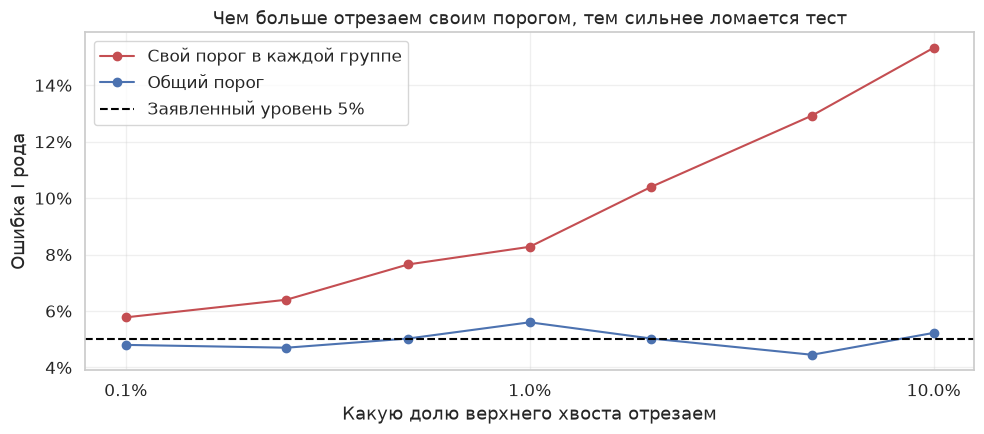

In [23]:
rng = np.random.default_rng(42)
tail_shares = np.array([0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.1])
per_group_fpr, pooled_fpr = [], []
for share in tail_shares:
    _, y_c = generate_revenue(rng, (4_000, 1_000))
    _, y_t = generate_revenue(rng, (4_000, 1_000))
    q_c = np.quantile(y_c, 1 - share, axis=1, keepdims=True)
    q_t = np.quantile(y_t, 1 - share, axis=1, keepdims=True)
    q_pooled = np.quantile(np.hstack([y_c, y_t]), 1 - share, axis=1, keepdims=True)
    for store, mask_c, mask_t in ((per_group_fpr, y_c <= q_c, y_t <= q_t), (pooled_fpr, y_c <= q_pooled, y_t <= q_pooled)):
        mean_c, var_c, n_c = masked_mean_var(y_c, mask_c)
        mean_t, var_t, n_t = masked_mean_var(y_t, mask_t)
        store.append(np.mean(z_pvalue(mean_t - mean_c, np.sqrt(var_c / n_c + var_t / n_t)) < ALPHA))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(tail_shares, per_group_fpr, 'o-', color=RED, label='Свой порог в каждой группе')
ax.plot(tail_shares, pooled_fpr, 'o-', color=BLUE, label='Общий порог')
ax.axhline(ALPHA, color='black', linestyle='--', label='Заявленный уровень 5%')
ax.set_xscale('log')
ax.set_xticks([0.001, 0.01, 0.1])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlabel('Какую долю верхнего хвоста отрезаем')
ax.set_ylabel('Ошибка I рода')
ax.set_title('Чем больше отрезаем своим порогом, тем сильнее ломается тест')
ax.legend()
plt.tight_layout()
plt.show()


#### Общий порог чинит A/A, но не A/B

Один порог на обе группы почти возвращает ошибку I рода к 5%. Но посмотрите на правый график: оценка эффекта занижена на четверть и больше. Причина одна для всех таких вариантов. **Удаление по значению метрики во время теста — это отбор по тому, на что повлияло воздействие.** В тесте выручка выросла, поэтому за порог уходит больше пользователей, и сравниваются уже разные наборы людей. Вдобавок эффект в хвосте просто отрезается.

Это относится и к порогу, посчитанному на предпериоде, если применять его к метрике во время теста: A/A почти в порядке, а эффект занижен так же. Сама по себе фиксация порога проблему не решает.

Корректные варианты:

* **Исключить пользователей по их поведению до теста.** Отбираем по значению на предпериоде, которое воздействие изменить не могло. Оценка почти не смещена, но это эффект на оставшихся пользователях.
* **Винзоризовать порогом с предпериода.** Значения выше порога не удаляются, а заменяются на порог: $\min(Y, q)$. Никого не выкидываем, состав групп не меняется, ошибка I рода корректна, а мощность немного выше, чем без очистки. Смещение остаётся, но оно меньше, и у него ясный смысл: это эффект на ограниченную сверху метрику.

На данных с лёгкими хвостами выигрыша может и не быть, поэтому эффект очистки стоит проверять на A/A- и A/B-симуляциях на своих данных. У новых пользователей нет предпериода, для них порог и правило заранее задаются отдельно.
